В цьому домашньому завданні ми з вами побудуємо повноцінне ML-рішення реальної ML-задачі. Ви вже маєте всі знання, які для цього потрібні. Дотримуйтесь інструкцій, та користуйтесь матеріалами лекцій, аби виконувати завдання. Тут інструкції будуть детальні, а в подільших завданнях - будуть ставати все менш детальними, аби ви вже починали самостійно структурувати ML-проєкт і до кінця курсу для вас розвʼязати будь-яку ML–задачу було eazy-breezy.

## Dataset

Будемо працювати з набором даних `cars.csv`, який описує автомобілі і їх ціну у індійських рупіях :) Мета - передбачити ціну авто за його характеристиками. Опис набору даних:

| Назва рядка            | Опис                                                                                                                                                 |
|------------------------|--------------------------------------------------------------------------------------------------------------------------------------------------------|
| Car_ID                 | Унікальний ідентифікатор для кожного оголошення про автомобіль.                                                                                         |
| Brand                  | Бренд або виробник автомобіля (наприклад, Toyota, Honda, Ford тощо).                                                                                     |
| Model                  | Модель автомобіля (наприклад, Camry, Civic, Mustang тощо).                                                                                               |
| Year                   | Рік виготовлення автомобіля.                                                                                                                            |
| Kilometers_Driven      | Загальний пробіг автомобіля у кілометрах.                                                                                                               |
| Fuel_Type              | Тип палива, який використовує автомобіль (наприклад, бензин, дизель, електро тощо).                                                                      |
| Transmission           | Тип трансмісії автомобіля (наприклад, механічна, автоматична).                                                                                           |
| Owner_Type             | Кількість попередніх власників автомобіля (наприклад, перший, другий, третій).                                                                           |
| Mileage                | Паливна ефективність автомобіля у кілометрах на літр.                                                                                                   |
| Engine                 | Об'єм двигуна автомобіля в кубічних сантиметрах (CC).                                                                                                   |
| Power                  | Максимальна потужність автомобіля в кінських силах (bhp).                                                                                               |
| Seats                  | Кількість місць в автомобілі.                                                                                                                           |
| Price                  | Вартість автомобіля в INR (індійські рупії), що є цільовою змінною для прогнозування.                                                                   |

# Імпорти

Для зручності рекомендую всі імпорти розмістити тут нагорі, аби коли ви перезавантажували ноутбук, одразу можна було в один запуск клітинки імпортувати всі потрібні бібліотеки.

In [133]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
%matplotlib inline
pd.set_option('display.max.rows',130)
pd.set_option('display.max.columns',130)
pd.set_option('display.float_format', '{:.2f}'.format)

# Знайомство з даними

**Завдання 1.** Завантажте набір даних `cars.csv` в pandas.DataFrame. Виведіть перші 5 записів.

In [134]:
cars_df = pd.read_csv('Materials/cars.csv')
cars_df.head(5)

,Car_ID,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
0,1,Toyota,Corolla,2018,50000,Petrol,Manual,First,15,1498,108,5,800000
1,2,Honda,Civic,2019,40000,Petrol,Automatic,Second,17,1597,140,5,1000000
2,3,Ford,Mustang,2017,20000,Petrol,Automatic,First,10,4951,395,4,2500000
3,4,Maruti,Swift,2020,30000,Diesel,Manual,Third,23,1248,74,5,600000
4,5,Hyundai,Sonata,2016,60000,Diesel,Automatic,Second,18,1999,194,5,850000


**Завдання 2.** Виведіть типи даних колонок даних, а також дослідіть, які по факту типи даних мають записи в кожній колонці (тип `object` може містити різні типи даних) і скільки значень є в кожній категоріальній колонці.

Напишіть висновок, скільки в наборі даних числових та категоріальних колонок кожного з трьох різних типів (бінарна, мільтикатегоріальна без порядку, мультикатегоріальна з порядком). Шаблон висновку

```
В наборі даних 10 числових і 10 категоріальних колонок з них
- 2 бінарні (мають лише 2 значення)
- 6 мультикатегоріальних (більше 2х значень) зі значеннями, для яких немає відношення порядку
- 2 колонки, в яких можна встановити відношення порядку (наприклад Small<Medium<Large)
```

Якщо не знаєте, як це зробити з `pandas` - ось підказка, які методи можуть допомогти вам виконати це завдання

- pandas.DataFrame.info()
- pandas.DataFrame.dtypes
- pandas.DataFrame.loc[...]
- pandas.DataFrame.select_dtypes(...)
- pandas.Series.unique()
- pandas.Series.nunique()

Детальніше ознайомитись з кожним ви можете в [документації](https://pandas.pydata.org/docs/reference/frame.html), або написати в окремій клітинці знак питання і назву методу (тільки приберіть це перед здачею, бо перегляд документації - не допомагає зрозуміти дані і хід думок, а Ваша робота - це як презентація замовнику зробленої задачі).


In [135]:
# приклад як викликати документацію, якщо у Вас pandas імпортований як pd
cars_df.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Car_ID             100 non-null    int64 
 1   Brand              100 non-null    object
 2   Model              100 non-null    object
 3   Year               100 non-null    int64 
 4   Kilometers_Driven  100 non-null    int64 
 5   Fuel_Type          100 non-null    object
 6   Transmission       100 non-null    object
 7   Owner_Type         100 non-null    object
 8   Mileage            100 non-null    int64 
 9   Engine             100 non-null    int64 
 10  Power              100 non-null    int64 
 11  Seats              100 non-null    int64 
 12  Price              100 non-null    int64 
dtypes: int64(8), object(5)
memory usage: 10.3+ KB


In [136]:
cars_df.shape

(100, 13)

### Спостереження
Маємо 13 колонок в датасеті. По 100 записів в кожній колонці, без пустих значень. Із співсатвлення назв і типів колонок бачим що одна перша колонка індекс є числовою - по змісту її варто віднести до категоріальної змінної тому змінимо її тип на стрінг.

In [137]:
cars_df['Car_ID'] = cars_df['Car_ID'].astype("str")

In [138]:
len(cars_df.select_dtypes(include="number").columns)

7

In [139]:
cars_df.describe()

,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price
count,100.00,100.00,100.00,100.00,100.00,100.00,100.00
mean,2018.39,28150.00,17.21,1855.23,158.13,5.23,1574000.00
std,1.17,9121.38,3.31,631.31,76.97,0.75,1000264.61
min,2016.00,10000.00,10.00,999.00,68.00,4.00,450000.00
25%,2017.75,22000.00,15.00,1462.00,103.00,5.00,700000.00
50%,2018.00,27000.00,17.00,1774.00,148.00,5.00,1300000.00
75%,2019.00,32000.00,19.00,2143.00,187.00,5.00,2500000.00
max,2021.00,60000.00,25.00,4951.00,396.00,7.00,4000000.00


In [140]:
cars_df.select_dtypes(include = "object").columns

Index(['Car_ID', 'Brand', 'Model', 'Fuel_Type', 'Transmission', 'Owner_Type'], dtype='object')

In [141]:
for col in cars_df.columns:
    print(f'\n{col} ({cars_df[col].nunique()} унікальних значень)')
    print(cars_df[col].value_counts(dropna=False))


Car_ID (100 унікальних значень)
Car_ID
1      1
64     1
74     1
73     1
72     1
71     1
70     1
69     1
68     1
67     1
66     1
65     1
63     1
2      1
62     1
61     1
60     1
59     1
58     1
57     1
56     1
55     1
54     1
53     1
75     1
76     1
77     1
78     1
99     1
98     1
97     1
96     1
95     1
94     1
93     1
92     1
91     1
90     1
89     1
88     1
87     1
86     1
85     1
84     1
83     1
82     1
81     1
80     1
79     1
52     1
51     1
50     1
25     1
23     1
22     1
21     1
20     1
19     1
18     1
17     1
16     1
15     1
14     1
13     1
12     1
11     1
10     1
9      1
8      1
7      1
6      1
5      1
4      1
3      1
24     1
26     1
49     1
27     1
48     1
47     1
46     1
45     1
44     1
43     1
42     1
41     1
40     1
39     1
38     1
37     1
36     1
35     1
34     1
33     1
32     1
31     1
30     1
29     1
28     1
100    1
Name: count, dtype: int64

Brand (11 унікальних значень)
Bra

Перевіримо значення числових колонок, їх розподіл і діапазони щоб визначити якщо є аномальні значення.

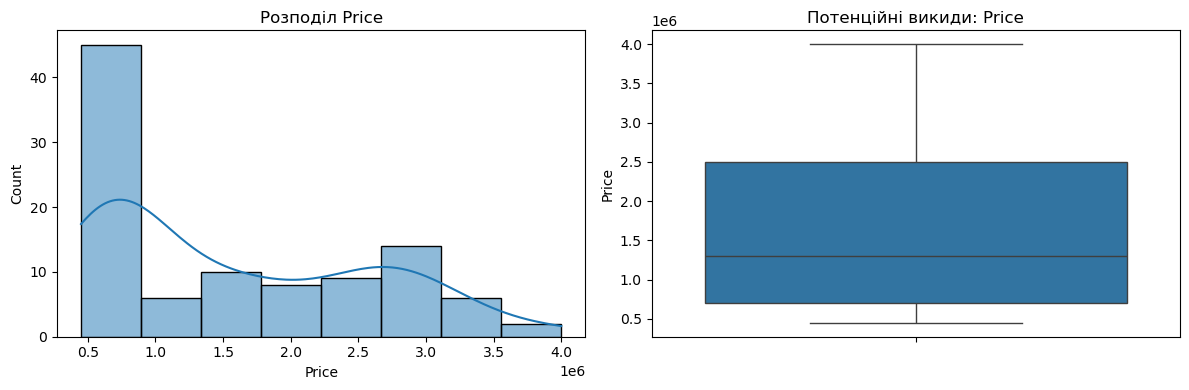

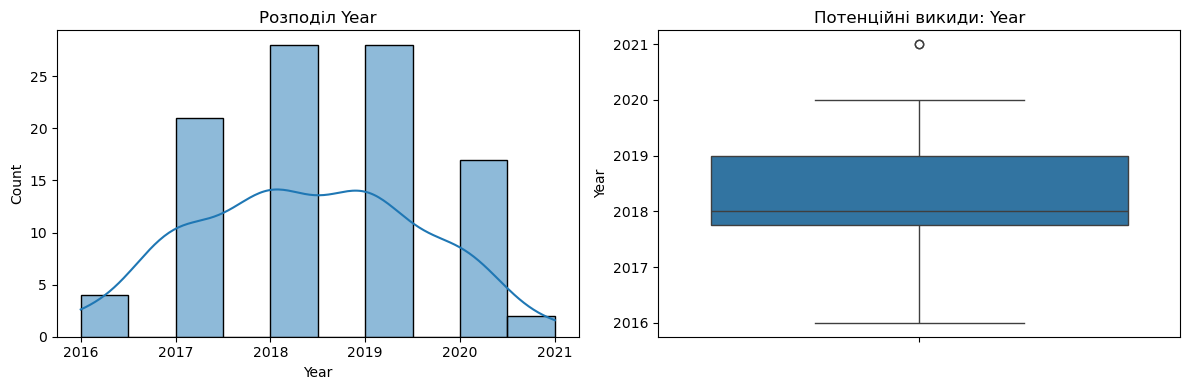

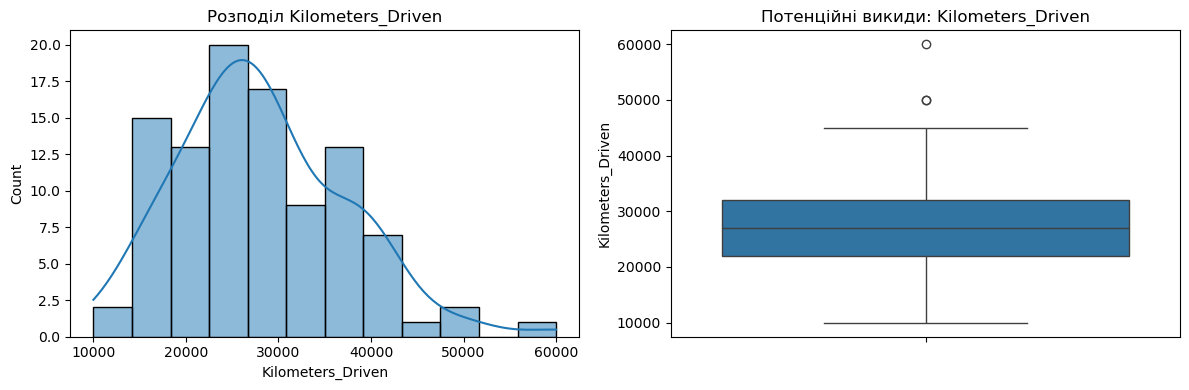

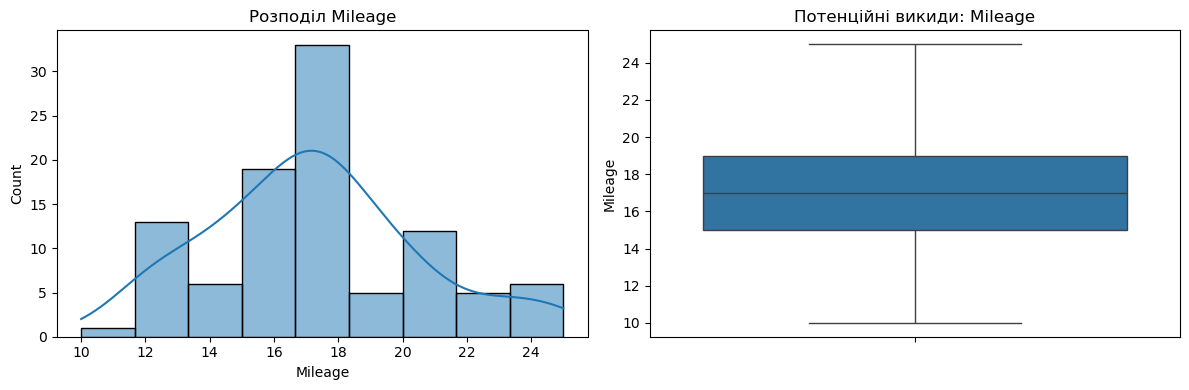

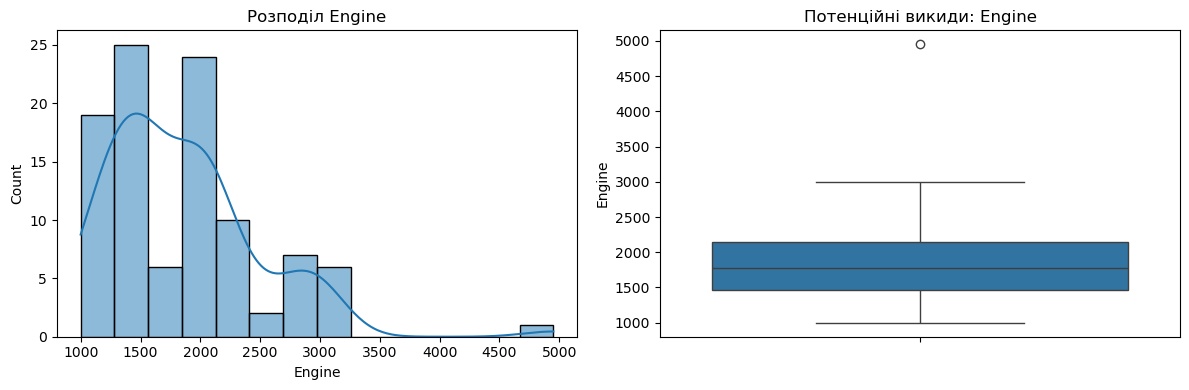

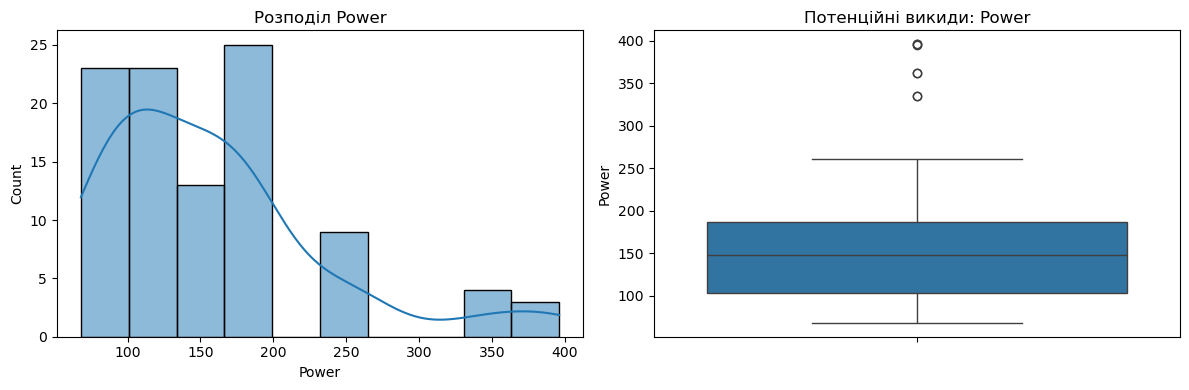

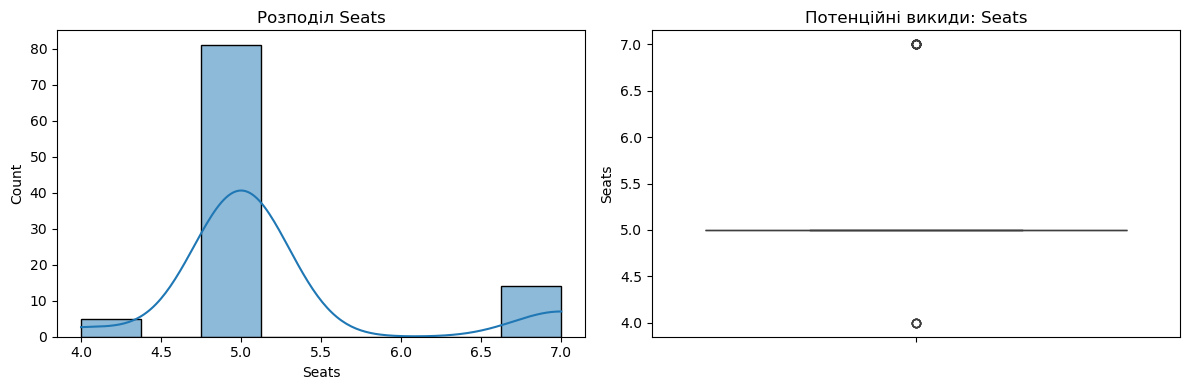

In [142]:
numeric_cols = ['Price', 'Year', 'Kilometers_Driven','Mileage', 'Engine', 'Power', 'Seats']

for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(data=cars_df, x=col, kde=True, ax=axes[0])
    axes[0].set_title(f'Розподіл {col}')

    sns.boxplot(data=cars_df, y=col, ax=axes[1])
    axes[1].set_title(f'Потенційні викиди: {col}')

    plt.tight_layout()
    plt.show()

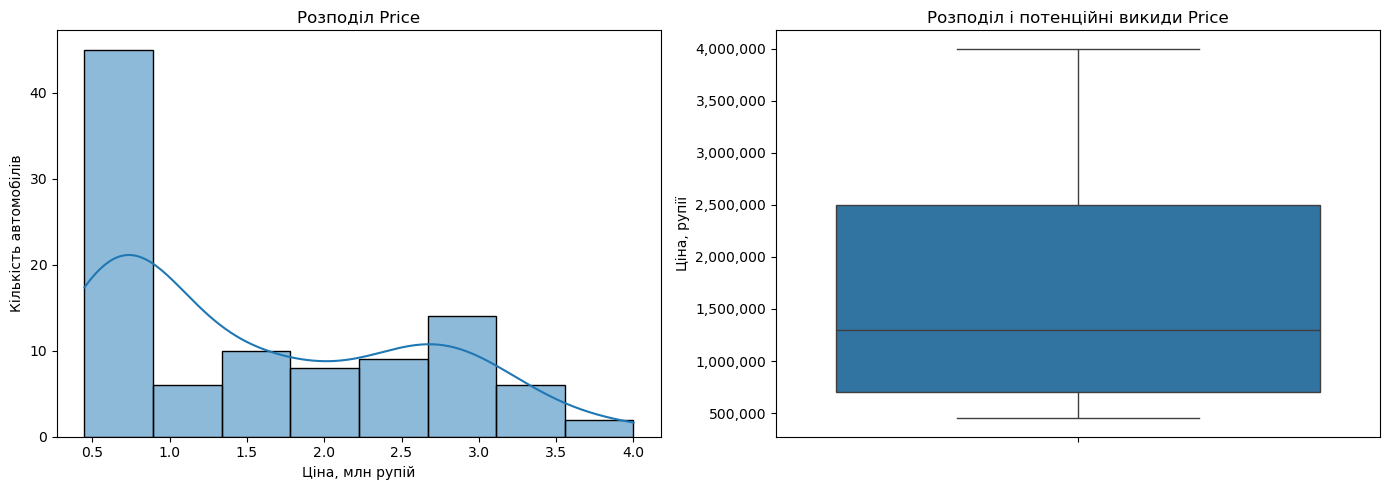

Мода:     850,000
Середнє:  1,574,000.00
Медіана:  1,300,000.00


In [143]:
from matplotlib.ticker import FuncFormatter, MultipleLocator

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гістограма
sns.histplot(data=cars_df, x='Price', kde=True, ax=axes[0])
axes[0].set_title('Розподіл Price')
axes[0].set_xlabel('Ціна, млн рупій')
axes[0].set_ylabel('Кількість автомобілів')
axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x / 1_000_000:.1f}')
)
axes[0].xaxis.set_major_locator(MultipleLocator(500_000))

# Boxplot
sns.boxplot(data=cars_df, y='Price', ax=axes[1])
axes[1].set_title('Розподіл і потенційні викиди Price')
axes[1].set_ylabel('Ціна, рупії')
axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}')
)

plt.tight_layout()
plt.show()

print(f"Мода:     {cars_df.Price.mode()[0]:,.0f}")
print(f"Середнє:  {cars_df.Price.mean():,.2f}")
print(f"Медіана:  {cars_df.Price.median():,.2f}")

Найпопулярніша ціна - 850 000, вона меньше середнього значення, що говорить про вплив на середнє великих значень.

Побудуємо scatterplot для кожної характеристики щоб бачити залежність ціни

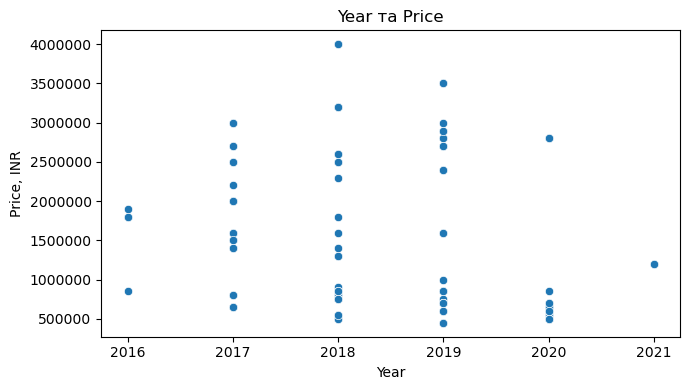

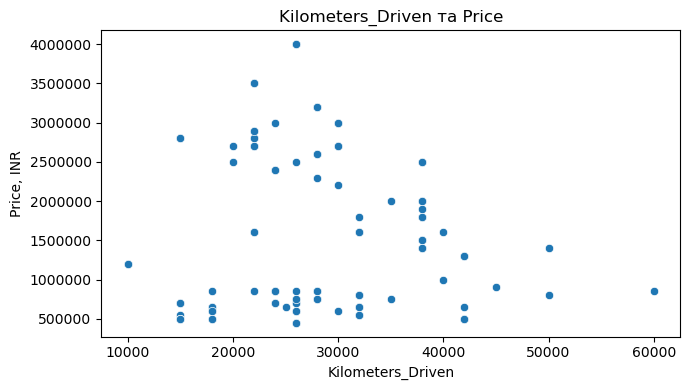

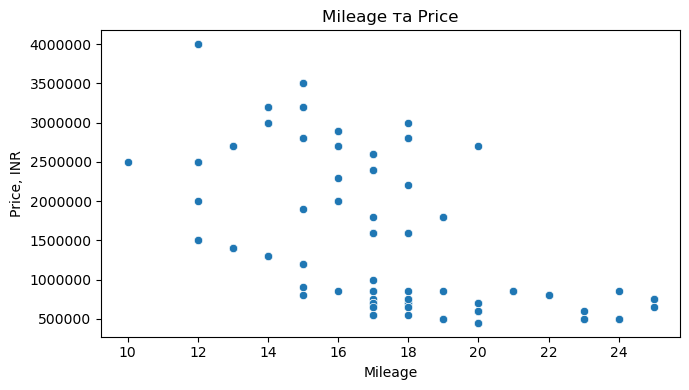

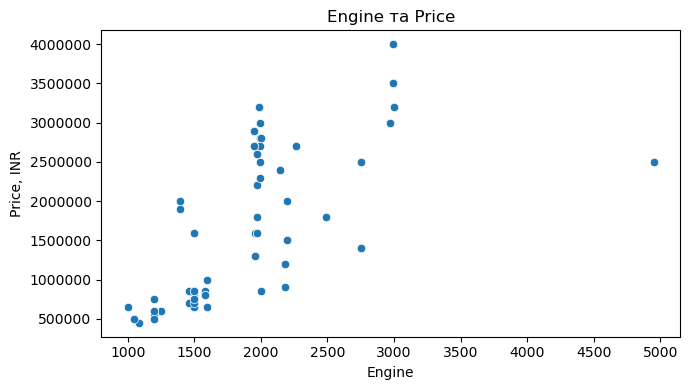

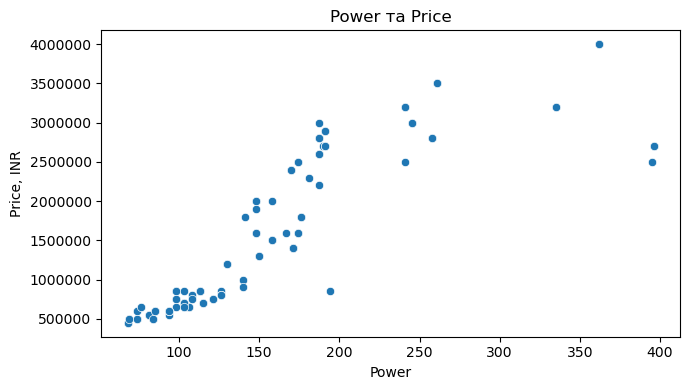

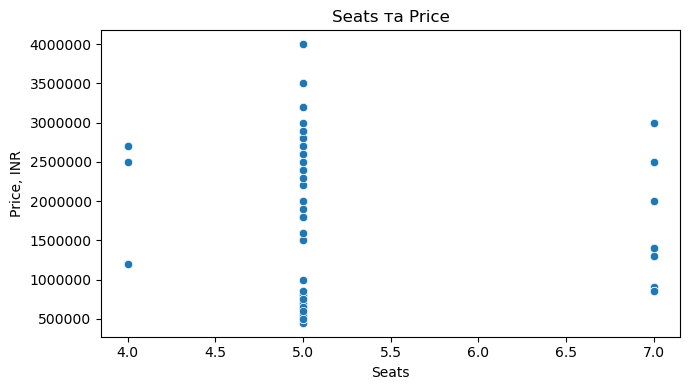

In [144]:
features = ['Year', 'Kilometers_Driven','Mileage', 'Engine', 'Power', 'Seats']

for col in features:
    plt.figure(figsize=(7, 4))

    sns.scatterplot(data=cars_df, x=col, y='Price')

    plt.title(f'{col} та Price')
    plt.xlabel(col)
    plt.ylabel('Price, INR')
    plt.ticklabel_format(axis='y', style='plain')
    plt.tight_layout()
    plt.show()

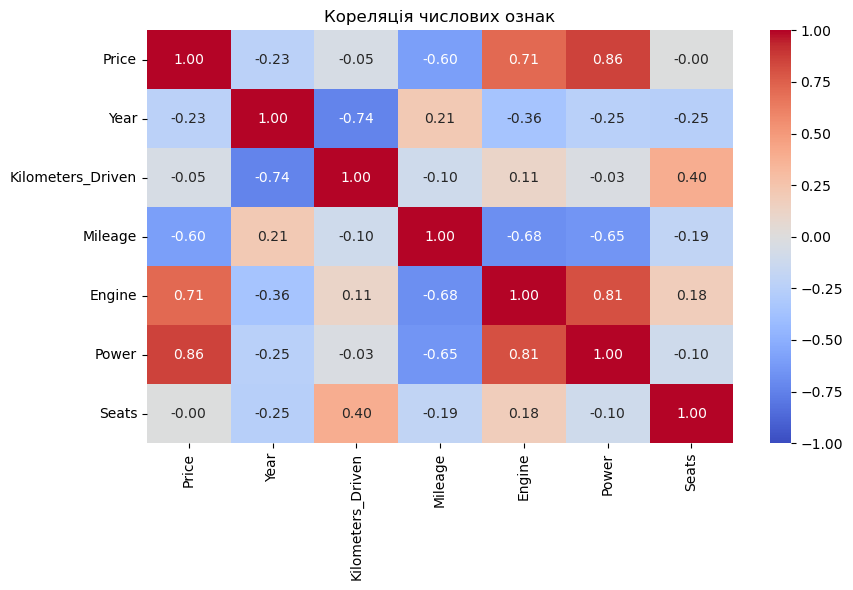

In [145]:
corr = cars_df[numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Кореляція числових ознак')
plt.tight_layout()
plt.show()

По числовим колонкам найбільшу кореляцію має 'Engine' 'Power' обєм двигуна та паливна потужність, більш слабшу зворотну кореляцію має витрати палива на кілометр. Рік і пробіг автомобіля мають меншу кореляцію, але тут може бути залежність з моделлю автомобіля і маркою.

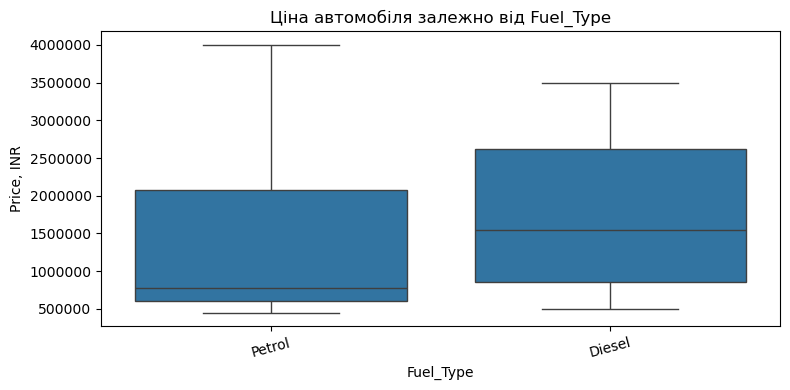

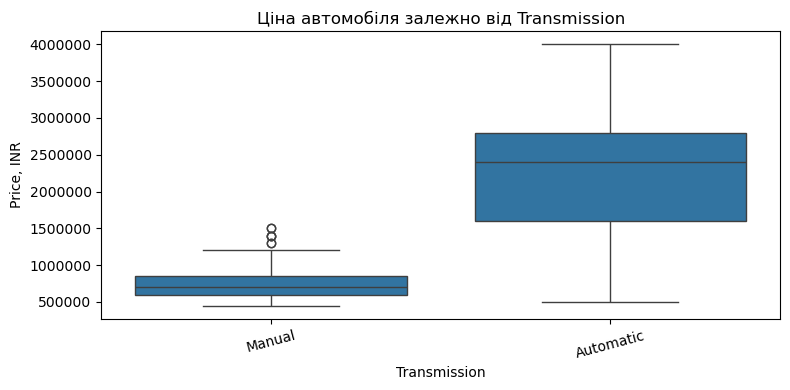

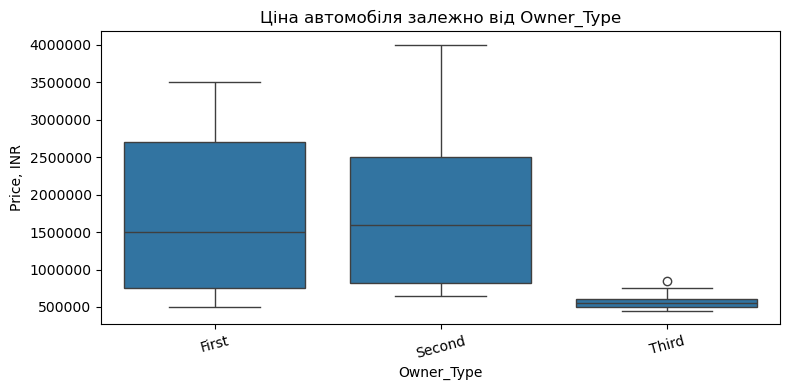

In [146]:
for col in ['Fuel_Type', 'Transmission', 'Owner_Type']:
    plt.figure(figsize=(8, 4))

    sns.boxplot(data=cars_df, x=col, y='Price')

    plt.title(f'Ціна автомобіля залежно від {col}')
    plt.xlabel(col)
    plt.ylabel('Price, INR')
    plt.ticklabel_format(axis='y', style='plain')
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

По категоріальним змінним бачимо що велике значення має тип трансмісії - автомат коштує корожче за механічну коробку. Частковий вплив теж матиме номер власника. Якщо у автомобіля було три власника він коштує дешевше, проте тут данних не так багато.
Дизельні автомобілі коштують дорожче.

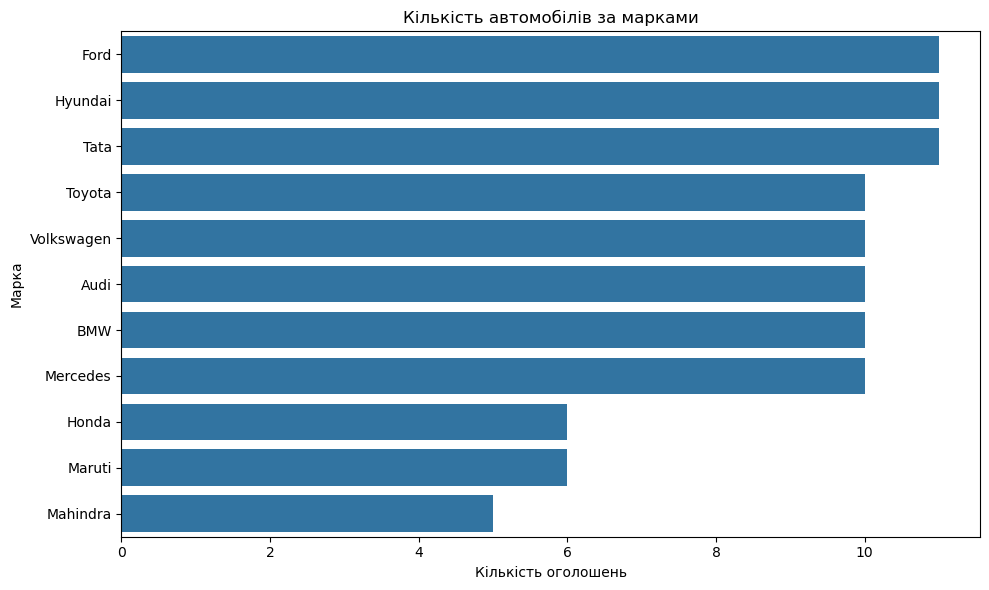

In [147]:
brand_counts = cars_df['Brand'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=brand_counts.values, y=brand_counts.index)

plt.title('Кількість автомобілів за марками')
plt.xlabel('Кількість оголошень')
plt.ylabel('Марка')
plt.tight_layout()
plt.show()

In [148]:
print('Усього унікальних моделей:', cars_df['Model'].nunique())

print(cars_df['Model'].value_counts().head(20))

Усього унікальних моделей: 58
Model
Mustang     3
Altroz      3
C-Class     3
Verna       3
Fortuner    2
S-Cross     2
Vitara      2
WR-V        2
Ameo        2
A3          2
7 Series    2
GLE         2
Yaris       2
Ranger      2
Santro      2
Tigor       2
T-Roc       2
BR-V        2
Elantra     2
Q7          2
Name: count, dtype: int64


In [149]:
brand_model_counts = (
    cars_df.groupby(['Brand', 'Model'])
    .size()
    .reset_index(name='Count')
    .sort_values(['Brand', 'Count'], ascending=[True, False])
)

print(brand_model_counts)

         Brand          Model  Count
0         Audi             A3      2
2         Audi             A5      2
3         Audi             A6      2
5         Audi             Q7      2
1         Audi             A4      1
4         Audi             Q3      1
6          BMW       3 Series      2
8          BMW       7 Series      2
10         BMW             X3      2
11         BMW             X5      2
7          BMW       5 Series      1
9          BMW             X1      1
16        Ford        Mustang      3
12        Ford         Aspire      2
13        Ford       EcoSport      2
17        Ford         Ranger      2
14        Ford      Endeavour      1
15        Ford           Figo      1
18       Honda           BR-V      2
21       Honda           WR-V      2
19       Honda           City      1
20       Honda          Civic      1
27     Hyundai          Verna      3
23     Hyundai        Elantra      2
24     Hyundai         Santro      2
26     Hyundai          Venue      2
2

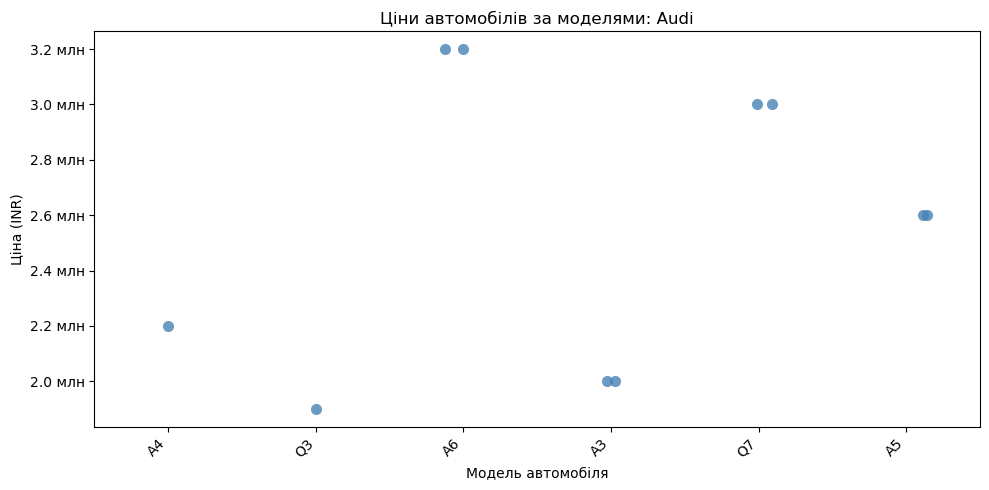

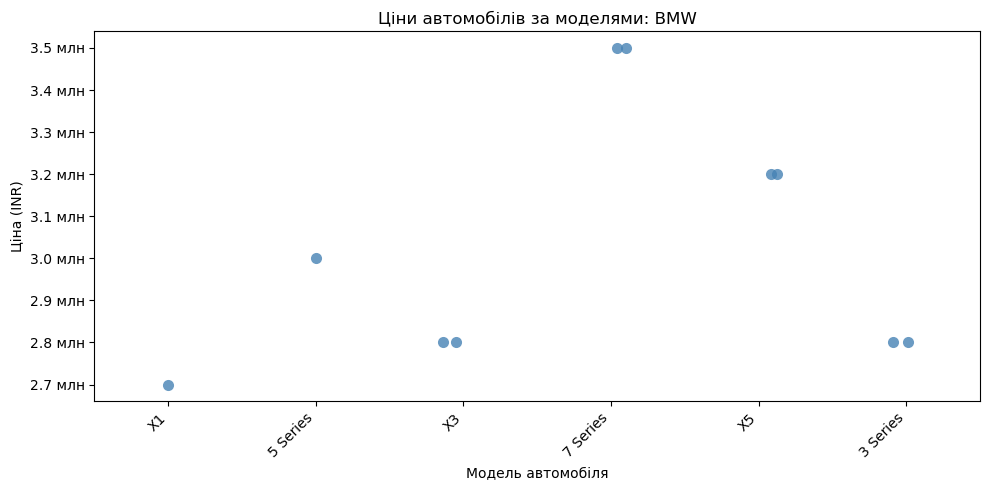

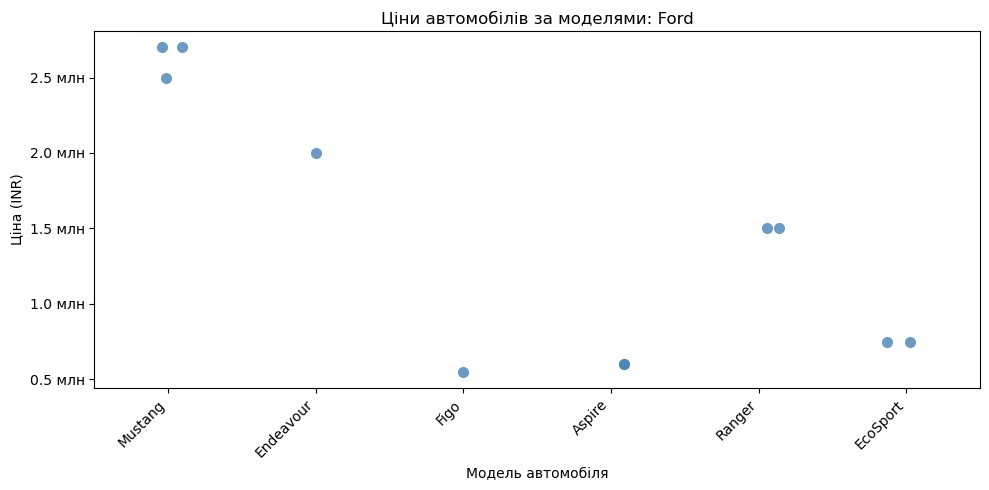

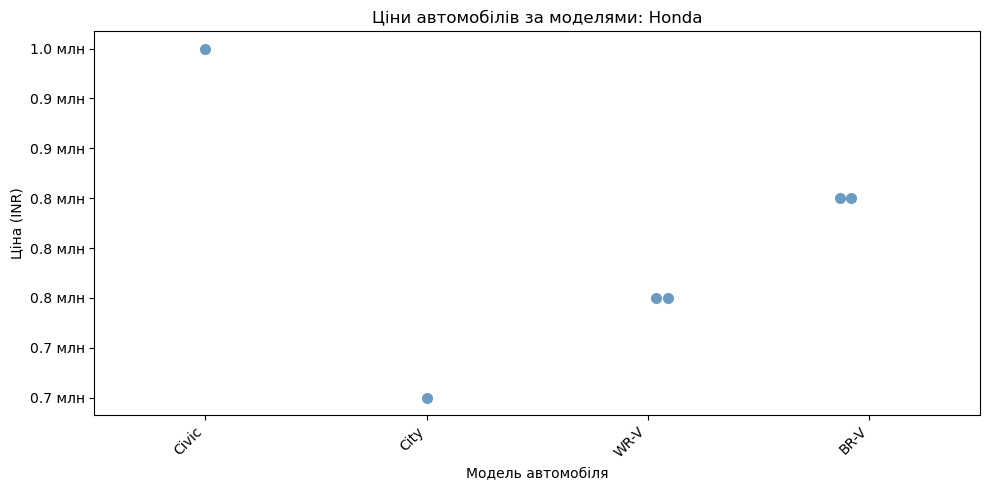

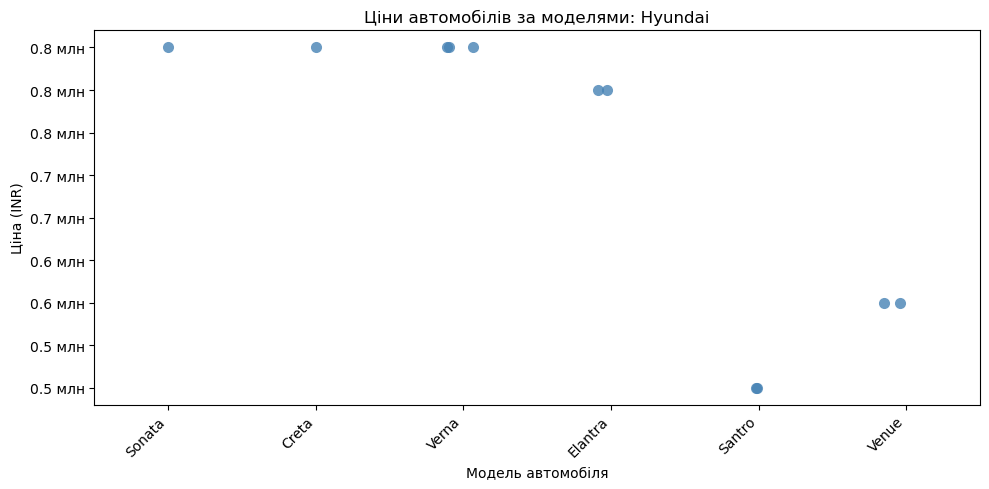

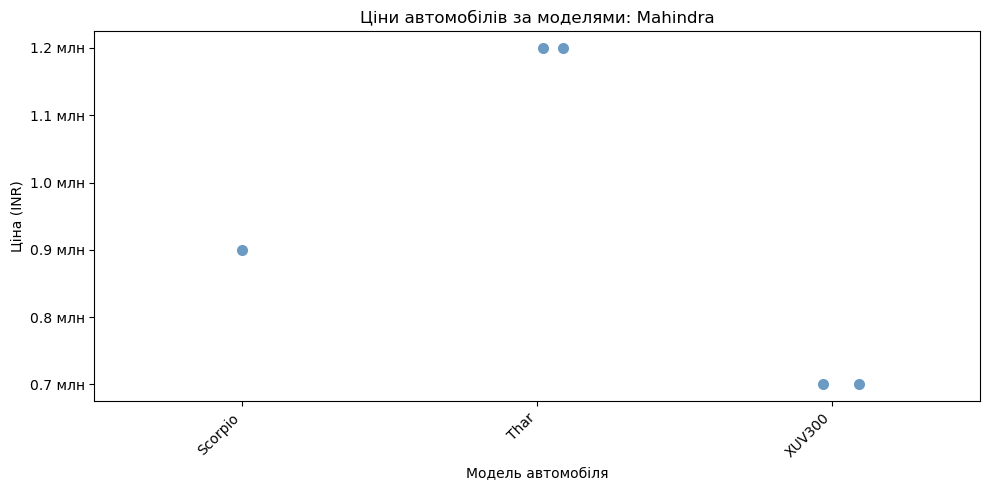

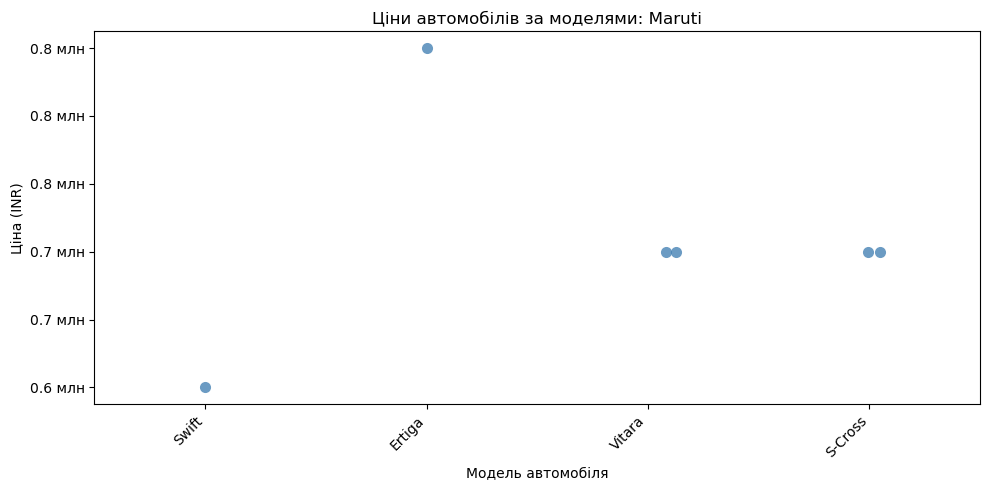

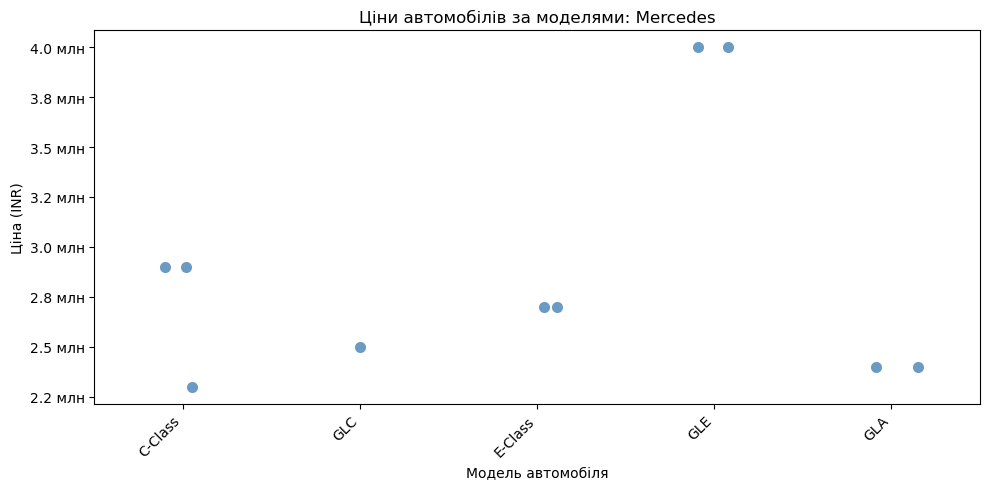

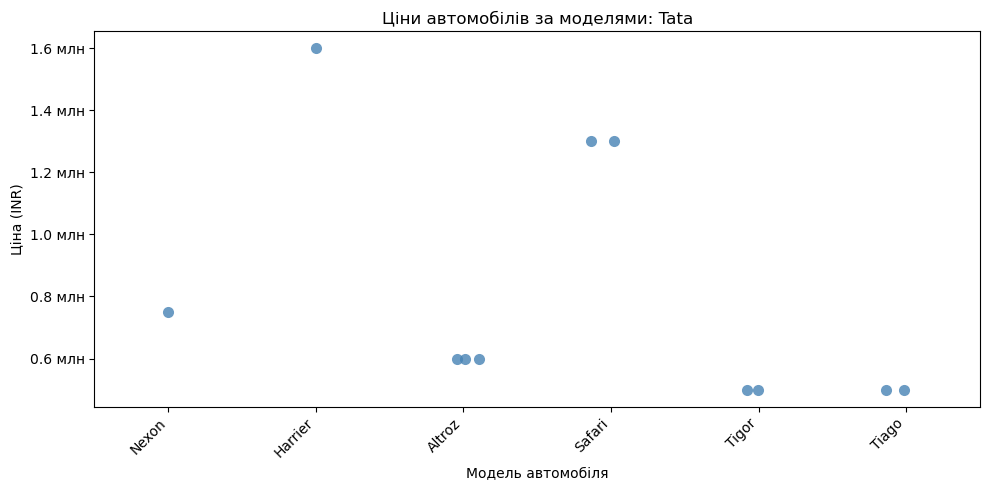

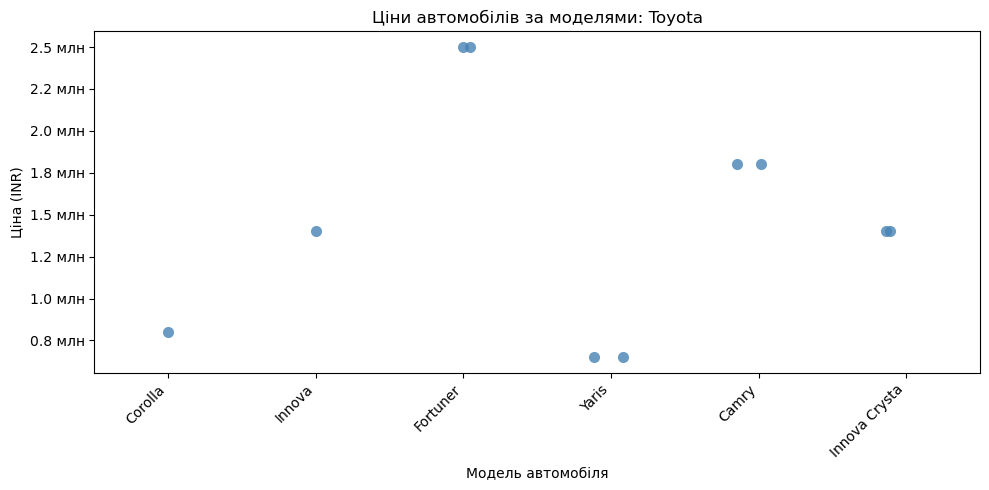

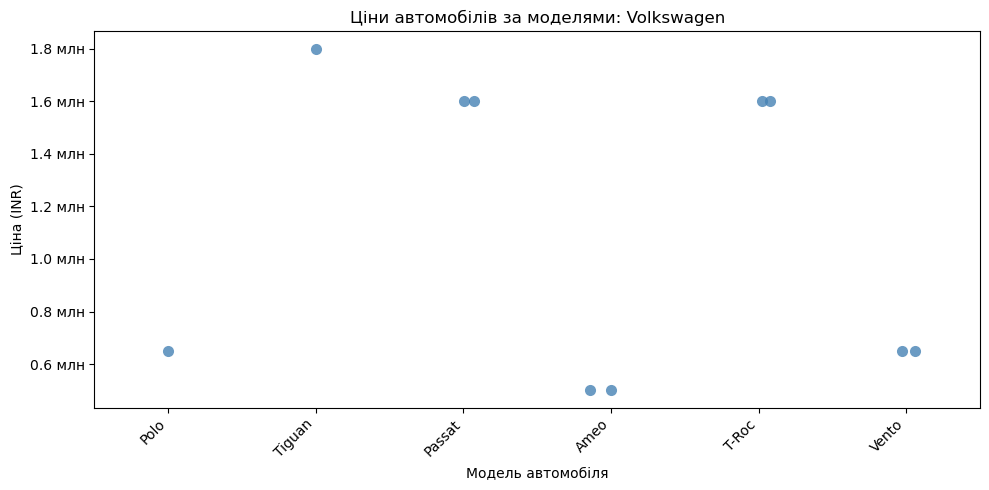

In [150]:
from matplotlib.ticker import FuncFormatter

brands = sorted(cars_df['Brand'].dropna().unique())

for brand in brands:
    brand_df = cars_df[cars_df['Brand'] == brand]

    plt.figure(figsize=(10, 5))

    sns.stripplot(
        data=brand_df,
        x='Model',
        y='Price',
        jitter=0.15,
        size=8,
        color='steelblue',
        alpha=0.8
    )

    plt.title(f'Ціни автомобілів за моделями: {brand}')
    plt.xlabel('Модель автомобіля')
    plt.ylabel('Ціна (INR)')

    plt.gca().yaxis.set_major_formatter(
        FuncFormatter(lambda x, _: f'{x / 1_000_000:.1f} млн')
    )

    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

Car_ID - Унікальний номер машини в базі (мультикатегоріальна колонка) - не буде нам потрібна для моделі оскільки ніякої цінності смислової для нас не несе.  
Brand - мультикатегоріальна колонка (має бренд автомобіля і більше 2 значень унікальних в колонці)  
Model -  мультикатегоріальна колонка більше 2 значень унікальних в колонці, по графікам бачимо що вартість автомобіля в рамках кожної моделі приблизно в одному діапазоні, тому можна розділити автомобілі по класу вартості (бюджетні, середній сегмент, бізнес і преміум в залезності діапазонів цін)  
Fuel_Type, Transmission - категоріальні бінарні змінні що мають по два унікальні значення, можна з них зробити флаги Is_Petrol (1 - Petrol, 0 - Diesel) Is_Automatic (1 - Automatic, 0 - Manual)  
Owner_Type - категоріальна змінна що має три значення в яких можна встановити відношення порядку (перетворимо на числову зі значеннями 1, 2, 3).  
Та числові колонки
Year, Kilometers_Driven, Mileage, Engine, Power, Seats, Price

В наборі даних 7 числових і 6 категоріальних колонок (після перетворення колонки Car_ID в категораільну) з них
- 2 бінарні (мають лише 2 значення) (Fuel_Type, Transmission)
- 3 мультикатегоріальних (більше 2х значень) зі значеннями, для яких немає відношення порядку (Car_ID, Brand, Model) 
- 1 колонка (Owner_Type), в якій можна встановити відношення порядку (1, 2, 3)

**Завдання 3**. Розділіть дані на тренувальні і тест. Відведіть в тест 20%, поставте `random_state=12`. Ми будемо передбачати колонку `Price` - тож, вона є цільовою змінною. В результаті у Вас має бути 4 набори даних `X_train, X_test, y_train, y_test`.

Надалі ми всюди тренуємо методи для кодування, масштабування та саму модель тільки на тренувальних даних X_train (та y_train для моделі), а на тестувальних лише використовуємо вже навчені методи для кодування, масштабування і модель викликаючи в них `transform()` (для методів обробки даних) або `predict()` (для моделі).

І так само треба робити завжди.

In [151]:
# Цільова змінна — ціна автомобіля
targets = cars_df['Price']

# Ознаки: усі колонки, крім Price та Car_ID
inputs = cars_df.drop(columns=['Price', 'Car_ID'])
X_train, X_test, y_train, y_test = train_test_split(inputs, targets, test_size=0.2, random_state=12)

In [152]:
print('Навчальні ознаки:', X_train.shape)
print('Тестові ознаки:', X_test.shape)

print('Навчальні цілі:', y_train.shape)
print('Тестові цілі:', y_test.shape)

Навчальні ознаки: (80, 11)
Тестові ознаки: (20, 11)
Навчальні цілі: (80,)
Тестові цілі: (20,)


**Завдання 4**. Кодуємо категоріальні колонки.

1. Закодуйте колонки з бінарними значеннями `Fuel_Type` і `Transmission` так, аби вони були у чисельному представленні і містили лише 0 так 1. Приклад був у лекції. Значення 1 нехай буде у категорії, яка містить більше значень в колонці.

2. Закодуйте колонку `Brand` з використанням `sklearn.preprocessing.OneHotEncoder` аналогічно до того, як ми робили це в лекції. Увага! Ми робимо виклик методу `Encoder.fit()` на тренувальних даних `X_train`, а на тестувальних тільки викликаємо `Encoder.transform()`. Додайте закодовані значення в набори даних `X_train`, `X_test`.

3. Колонку `Owner_Type` з використанням `sklearn.preprocessing.OrdinalEncoder` я закодую для вас. Проаналізуйте, що відбувається.

Колонка `Model` містять забагато значень для кодування в тому вигляді, як вона є зараз, з огляду на невелику кількість даних. Якщо ви бачите, як можна згрупувати значення в цій колонці скоротивши кількість унікальних значень до 3-5, то можете виконати ще цю трансформацію, використати цю колонку в моделі і отримати додаткову практику і бал, якщо все буде зроблено правильно. А якщо неправильно - то фідбек на Вашу роботу :)

In [153]:
# Кодування Fuel_Type
Is_Petrols = {'Diesel': 0, 'Petrol': 1}

X_train['Is_Petrol'] = X_train['Fuel_Type'].map(Is_Petrols)
X_test['Is_Petrol'] = X_test['Fuel_Type'].map(Is_Petrols)

# Кодування Transmission
Is_Automatics = {'Manual': 0, 'Automatic': 1}

X_train['Is_Automatic'] = X_train['Transmission'].map(Is_Automatics)
X_test['Is_Automatic'] = X_test['Transmission'].map(Is_Automatics)

In [154]:
X_train.head()

,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Is_Petrol,Is_Automatic
83,Volkswagen,T-Roc,2019,22000,Petrol,Automatic,Second,18,1498,148,5,1,1
55,Audi,A5,2018,28000,Diesel,Automatic,First,17,1968,187,5,0,1
26,Audi,A6,2018,28000,Petrol,Automatic,First,15,1984,241,5,1,1
54,Volkswagen,Vento,2017,32000,Petrol,Manual,Second,18,1598,103,5,1,0
19,Mercedes,GLC,2017,26000,Petrol,Automatic,Second,12,1991,241,5,1,1


In [155]:
# 1. Створюємо кодувальник
enc_brand = preprocessing.OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# 2. Навчаємо лише на тренувальних даних
enc_brand.fit(X_train[['Brand']])

# 3. Кодуємо train і test однаковим способом
brand_train = enc_brand.transform(X_train[['Brand']])
brand_test = enc_brand.transform(X_test[['Brand']])

# 4. Отримуємо назви нових колонок
brand_columns = enc_brand.categories_[0]

# 5. Додаємо нові колонки до train і test
X_train[brand_columns] = brand_train
X_test[brand_columns] = brand_test

In [156]:
X_train.head()

,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Is_Petrol,Is_Automatic,Audi,BMW,Ford,Honda,Hyundai,Mahindra,Maruti,Mercedes,Tata,Toyota,Volkswagen
83,Volkswagen,T-Roc,2019,22000,Petrol,Automatic,Second,18,1498,148,5,1,1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
55,Audi,A5,2018,28000,Diesel,Automatic,First,17,1968,187,5,0,1,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
26,Audi,A6,2018,28000,Petrol,Automatic,First,15,1984,241,5,1,1,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
54,Volkswagen,Vento,2017,32000,Petrol,Manual,Second,18,1598,103,5,1,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
19,Mercedes,GLC,2017,26000,Petrol,Automatic,Second,12,1991,241,5,1,1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00


In [157]:
X_test.head()

,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Is_Petrol,Is_Automatic,Audi,BMW,Ford,Honda,Hyundai,Mahindra,Maruti,Mercedes,Tata,Toyota,Volkswagen
17,Audi,Q3,2016,38000,Petrol,Automatic,Second,15,1395,148,5,1,1,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
41,Hyundai,Santro,2019,26000,Petrol,Manual,Third,20,1086,68,5,1,0,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00
92,Volkswagen,Vento,2017,32000,Petrol,Manual,Second,18,1598,103,5,1,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
14,Maruti,Ertiga,2020,18000,Petrol,Manual,First,19,1462,103,7,1,0,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
68,Ford,Aspire,2019,26000,Petrol,Manual,Third,20,1194,94,5,1,0,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [158]:
from sklearn.preprocessing import OrdinalEncoder

ordenc = OrdinalEncoder(categories=[['First', 'Second', 'Third']]) # визначаємо порядок категорій
ordenc.fit(X_train[['Owner_Type']])

X_train['Owner_Type_Codes'] = ordenc.transform(X_train[['Owner_Type']])
X_test['Owner_Type_Codes'] = ordenc.transform(X_test[['Owner_Type']])

Очікуваний результат після трансформацій:

In [159]:
pd.set_option('display.max_columns', 100)
display(X_train.head()), display(X_test.head())

,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Is_Petrol,Is_Automatic,Audi,BMW,Ford,Honda,Hyundai,Mahindra,Maruti,Mercedes,Tata,Toyota,Volkswagen,Owner_Type_Codes
83,Volkswagen,T-Roc,2019,22000,Petrol,Automatic,Second,18,1498,148,5,1,1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00
55,Audi,A5,2018,28000,Diesel,Automatic,First,17,1968,187,5,0,1,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
26,Audi,A6,2018,28000,Petrol,Automatic,First,15,1984,241,5,1,1,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
54,Volkswagen,Vento,2017,32000,Petrol,Manual,Second,18,1598,103,5,1,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00
19,Mercedes,GLC,2017,26000,Petrol,Automatic,Second,12,1991,241,5,1,1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00


,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Is_Petrol,Is_Automatic,Audi,BMW,Ford,Honda,Hyundai,Mahindra,Maruti,Mercedes,Tata,Toyota,Volkswagen,Owner_Type_Codes
17,Audi,Q3,2016,38000,Petrol,Automatic,Second,15,1395,148,5,1,1,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
41,Hyundai,Santro,2019,26000,Petrol,Manual,Third,20,1086,68,5,1,0,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00
92,Volkswagen,Vento,2017,32000,Petrol,Manual,Second,18,1598,103,5,1,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00
14,Maruti,Ertiga,2020,18000,Petrol,Manual,First,19,1462,103,7,1,0,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
68,Ford,Aspire,2019,26000,Petrol,Manual,Third,20,1194,94,5,1,0,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00


(None, None)

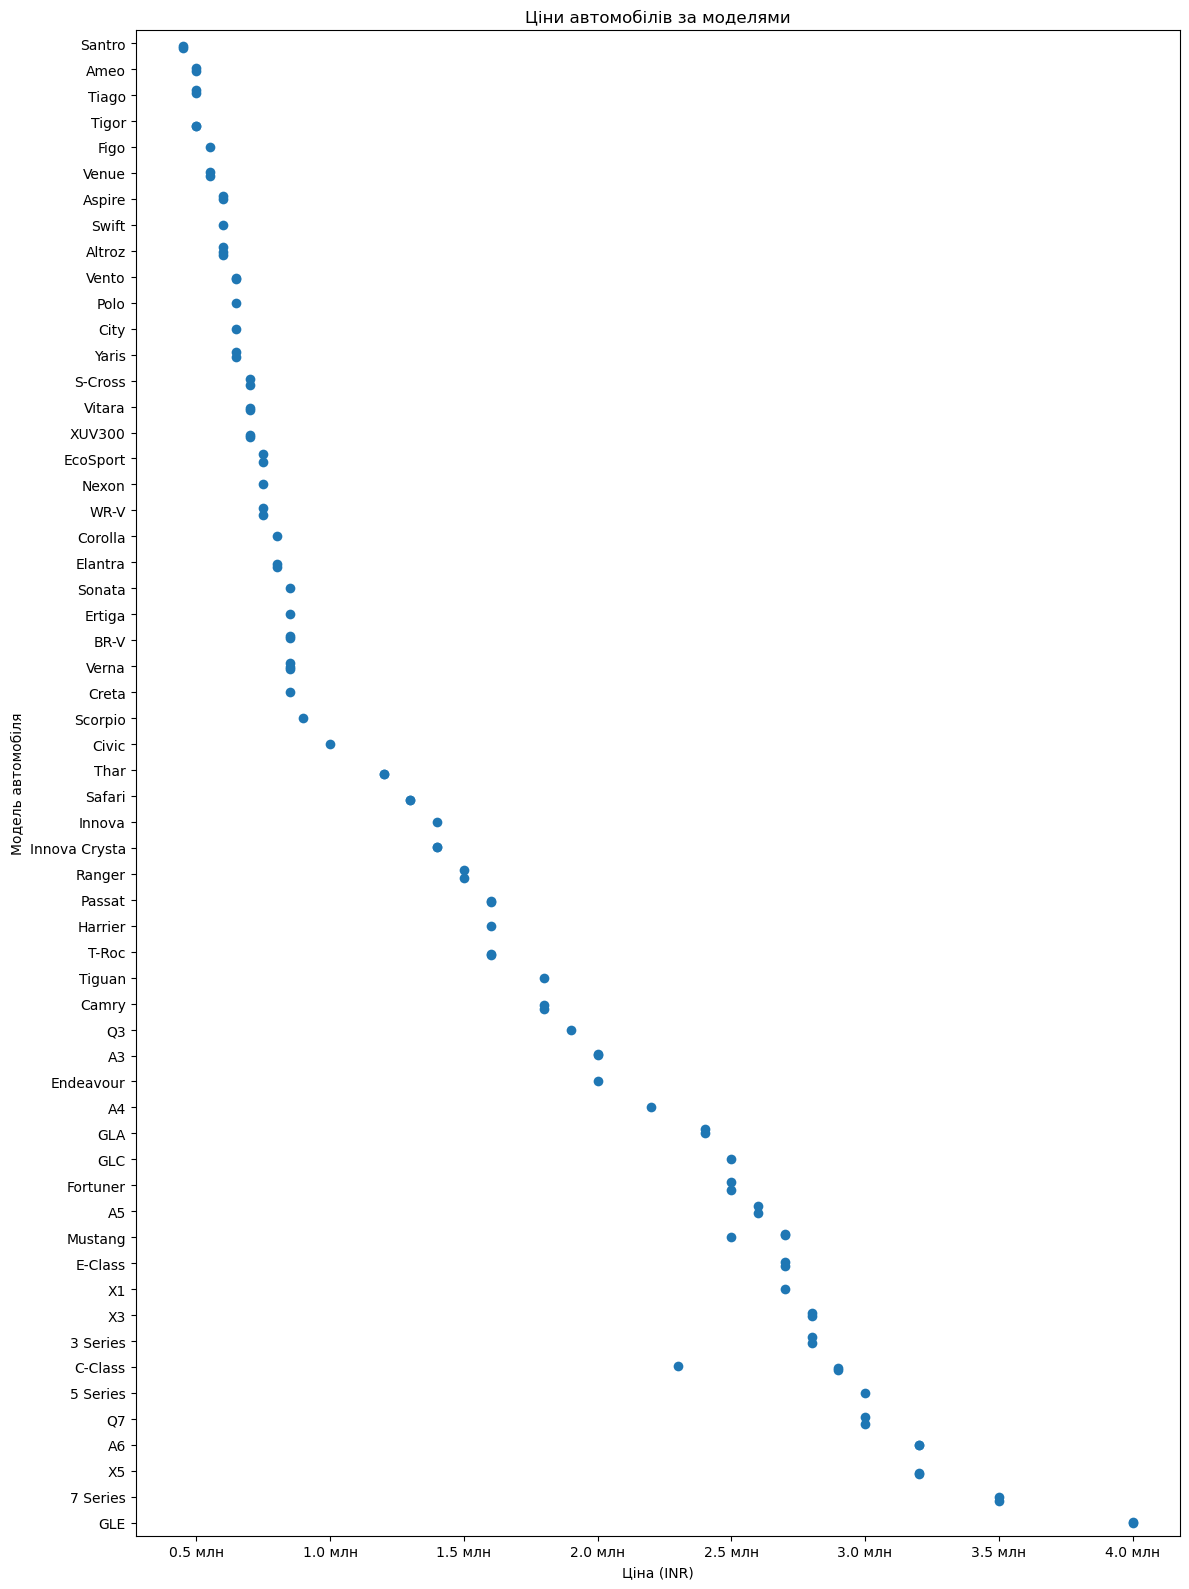

In [163]:
from matplotlib.ticker import FuncFormatter

# Сортуємо моделі за медіанною ціною
model_order = (
    cars_df.groupby('Model')['Price']
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(12, 16))

sns.stripplot(data=cars_df,
                x='Price',
                y='Model',
                order=model_order,
                jitter=0.2,
                size=7)

plt.title('Ціни автомобілів за моделями')
plt.xlabel('Ціна (INR)')
plt.ylabel('Модель автомобіля')

# Ціни в мільйонах рупій
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1_000_000:.1f} млн'))

plt.tight_layout()
plt.show()


Загалом ми бачимо що кожна модель знаходиться в певному діапазоні цін в нашому датасеті, тому логічно ми б могли поділити ціни на 3-5 категорій бюджетні, середнього цінового сегменту та преміум автомобілі і використати це в майбутньому. Проте з аналітичної точки зору на ціну має впливати не лише мдель а й пробіг, рік випуску, тому тут в реальних кейсах ділити діапазони по фактичній вартості можна десь не вгадати. Якби такий кейс був би в реальному житті я б поділила ці діапазони по фактичній вартості ринковій нового автомобіля. Тоді самі моделі були б співставні без урахування пробігів. 
Або інший варіант додати категорії автомобілів  бюджетний седан, базовий кросовер, пікам, преміальний - але тут теж буде вплив комплектації, просто з моделі таку інформацію взяти важко. Тому на цьому етапі вважаю що цю категорію візьмемо поки за дужки бо вона трохи суперечлива оскільки даних небагато і ми маємо вього по 1-2 записи по кожній моделі.

**Завдання 5.** Оберіть лише числові колонки з `X_train` (можна для цього використати `pandas.select_dtypes(...)` або видалити всі НЕчислові дані, вони нам вже не потрібні), обʼєднайте ці дані з `y_train` (зручно з `pandas.concat([df1, df2], axis=1)`), побудуйте для цих даних матрицю кореляції і проаналізуйте її. Напишіть висновок, які колонки корелюють з цільовою змінною на більш ніж 0.5 за модулем (може бути як позитивна, так і негативна кореляція).

In [164]:
# 1. Залишаємо лише числові колонки
X_train_numeric = X_train.select_dtypes(include='number')

# 2. Додаємо цільову змінну Price
train_numeric = pd.concat(
    [X_train_numeric, y_train.rename('Price')],
    axis=1
)

# Перевіряємо результат
display(train_numeric.head())
print('Кількість числових колонок:', train_numeric.shape[1])


,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Is_Petrol,Is_Automatic,Audi,BMW,Ford,Honda,Hyundai,Mahindra,Maruti,Mercedes,Tata,Toyota,Volkswagen,Owner_Type_Codes,Price
83,2019,22000,18,1498,148,5,1,1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1600000
55,2018,28000,17,1968,187,5,0,1,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2600000
26,2018,28000,15,1984,241,5,1,1,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3200000
54,2017,32000,18,1598,103,5,1,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,650000
19,2017,26000,12,1991,241,5,1,1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,2500000


Кількість числових колонок: 21


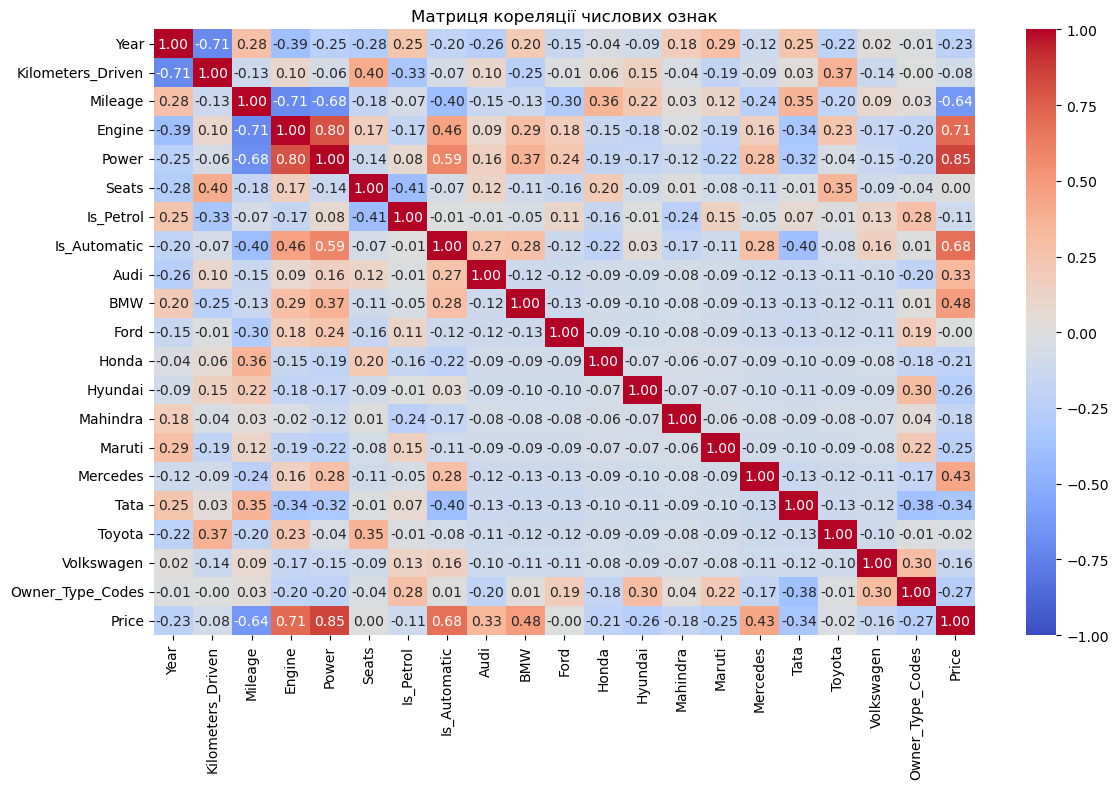

In [165]:
# Розраховуємо кореляції Пірсона
correlation_matrix = train_numeric.corr()

# Візуалізуємо матрицю
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Матриця кореляції числових ознак')
plt.tight_layout()
plt.show()

### Спостереження  
Найбільш корелюючі ознаки з ціною:  
Power (0,85) - Максимальна потужність автомобіля в кінських силах (bhp)  
Engine (0,71) - Об'єм двигуна автомобіля в кубічних сантиметрах (CC)  
Is_Automatic (0,68) - Тип трансмісії автомобіля  
Mileage	(-0,64) - зворотна кореляція Паливна ефективність автомобіля у кілометрах на літр


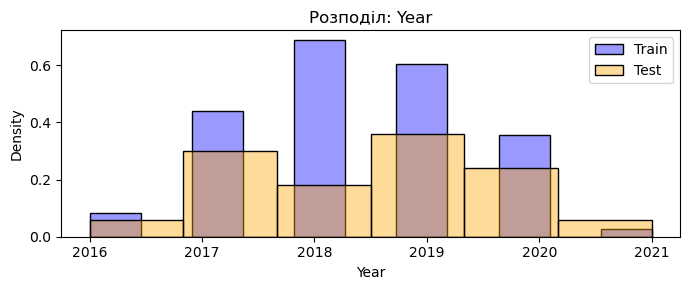

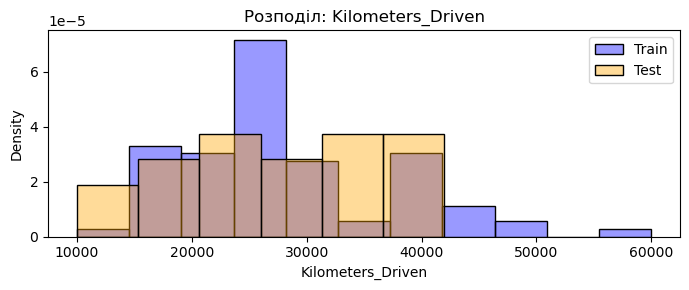

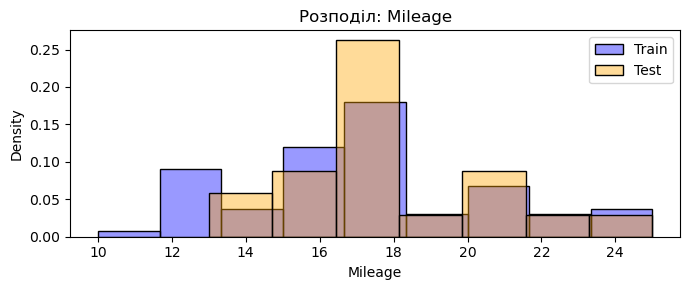

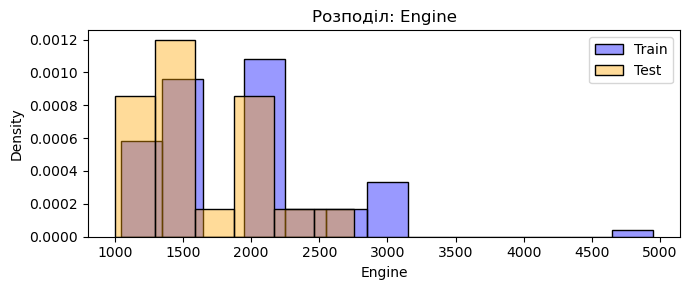

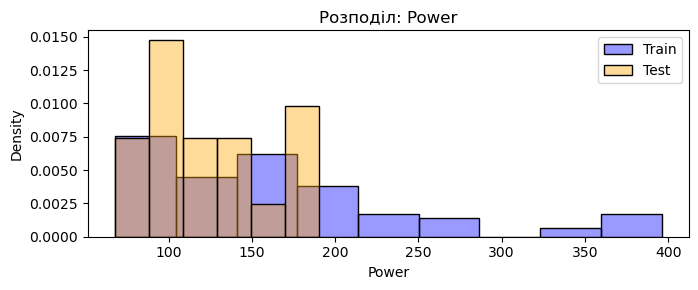

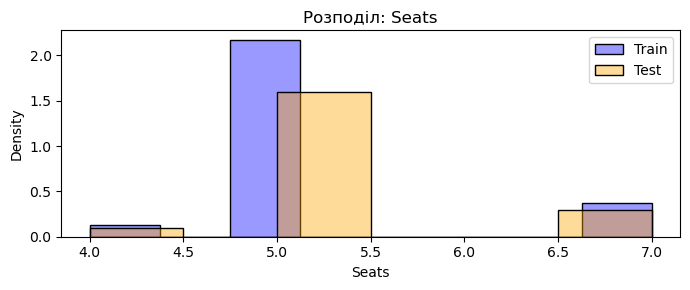

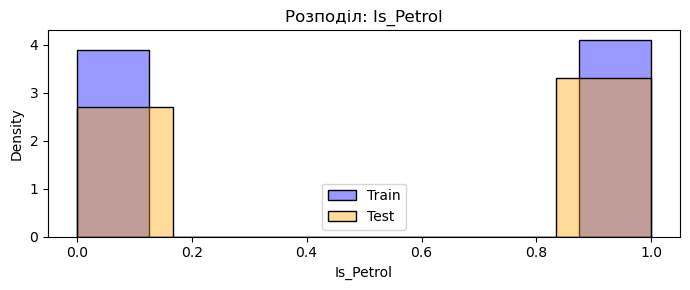

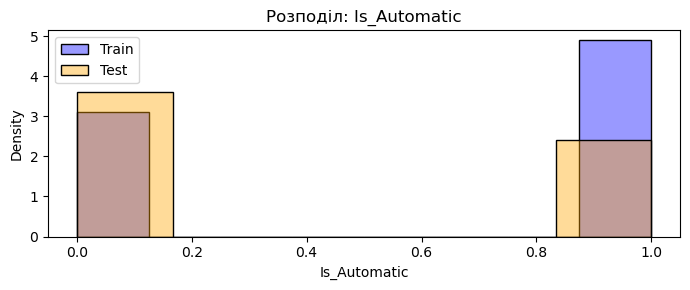

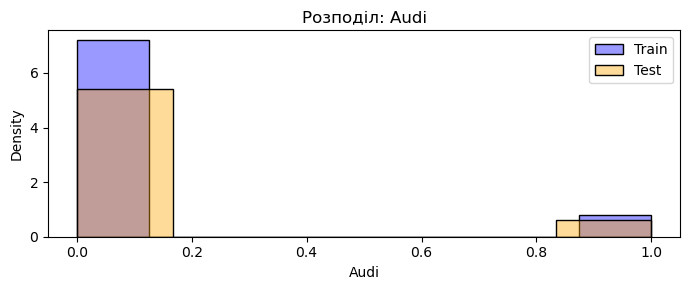

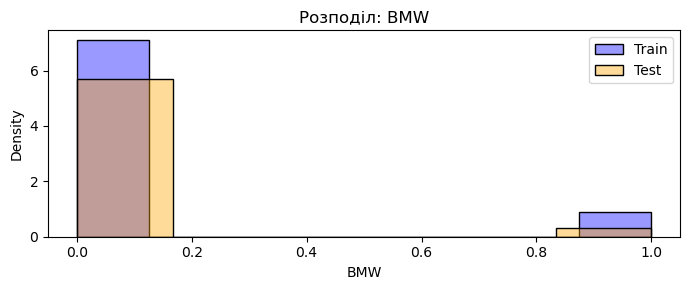

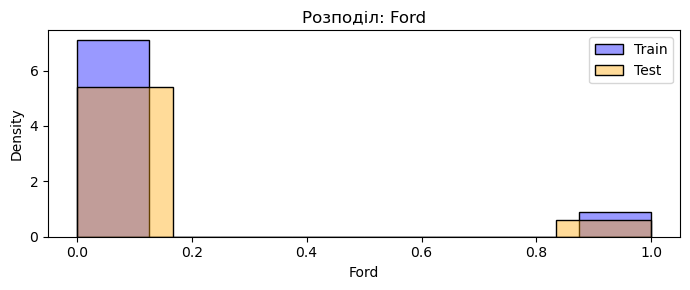

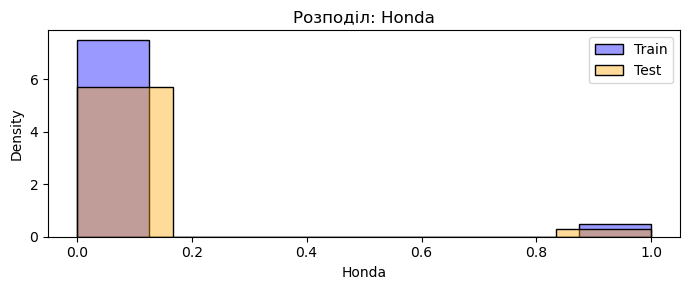

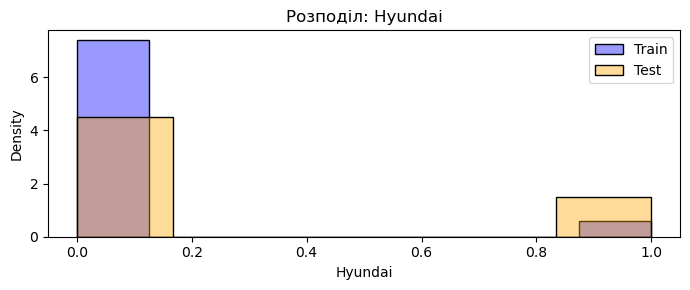

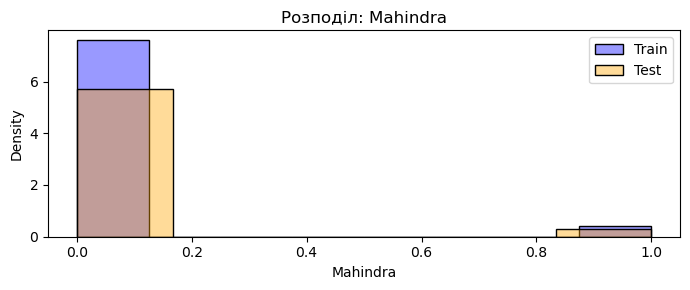

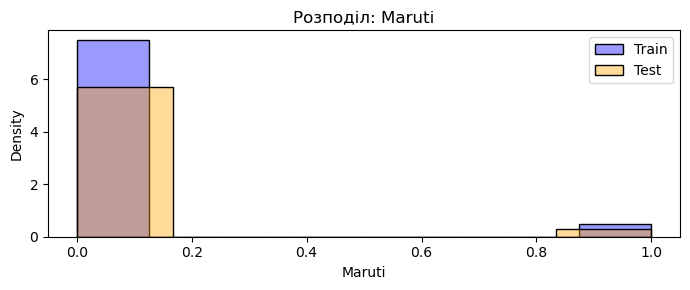

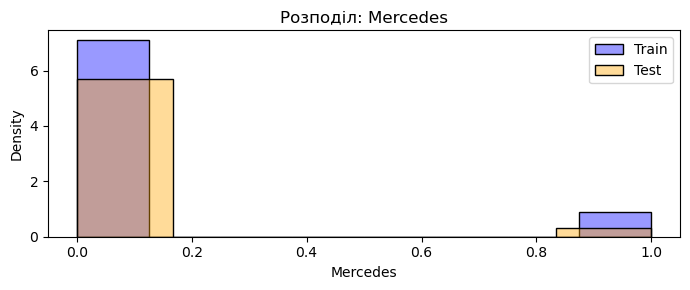

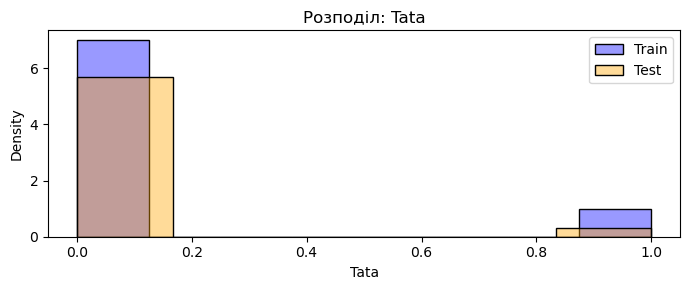

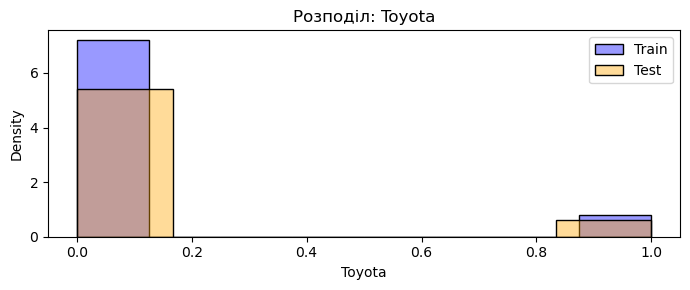

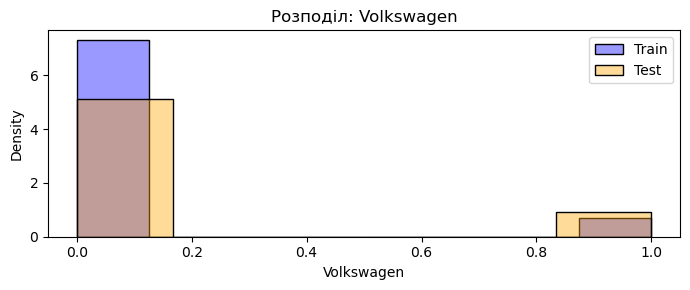

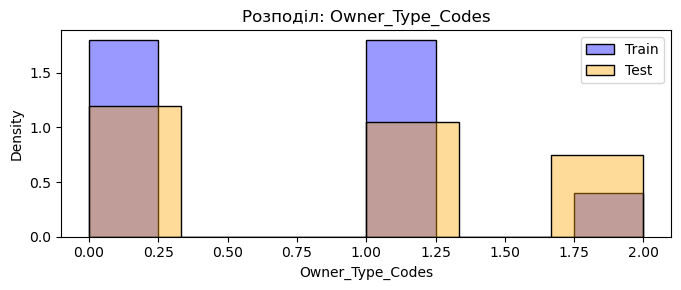

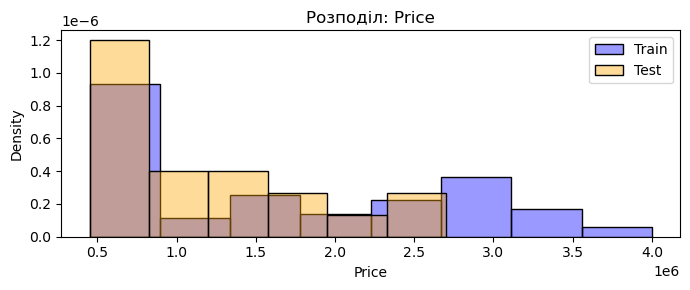

In [166]:
# Додаємо Price до train і test
train_plot = X_train.copy()
train_plot['Price'] = y_train

test_plot = X_test.copy()
test_plot['Price'] = y_test

# Числові колонки, спільні для train і test
num_cols = train_plot.select_dtypes(include='number').columns
num_cols = [c for c in num_cols if c in test_plot.columns]

for col in num_cols:
    plt.figure(figsize=(7, 3))
    sns.histplot(train_plot[col].dropna(), color='blue',
                 label='Train', stat='density', alpha=0.4)
    sns.histplot(test_plot[col].dropna(), color='orange',
                 label='Test', stat='density', alpha=0.4)
    plt.title(f'Розподіл: {col}')
    plt.legend()
    plt.tight_layout()
    plt.show()

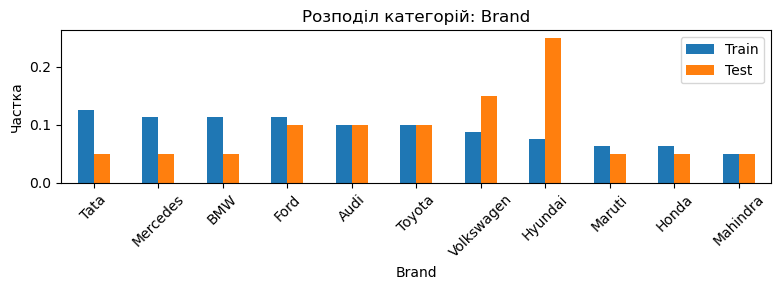

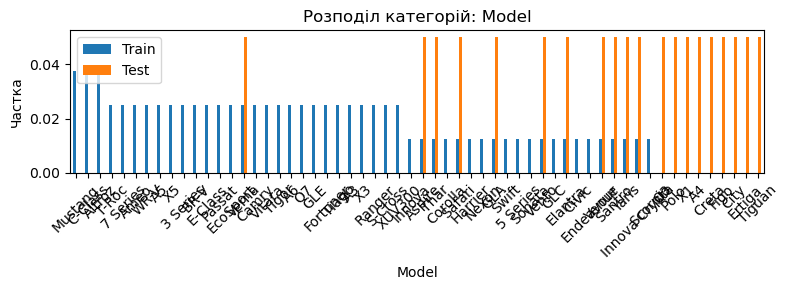

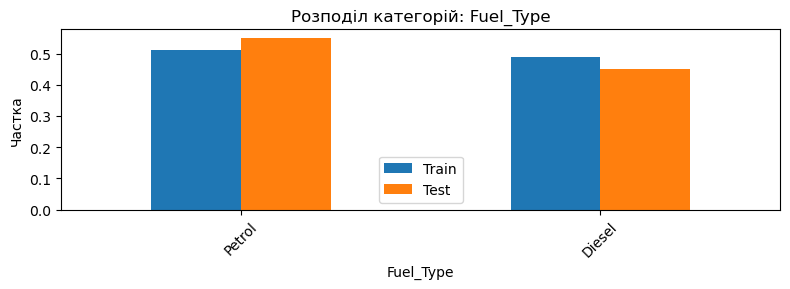

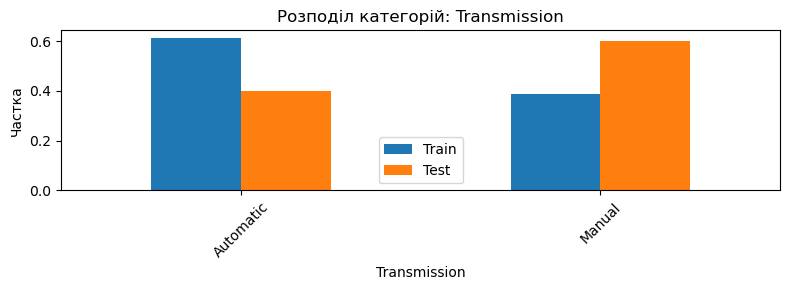

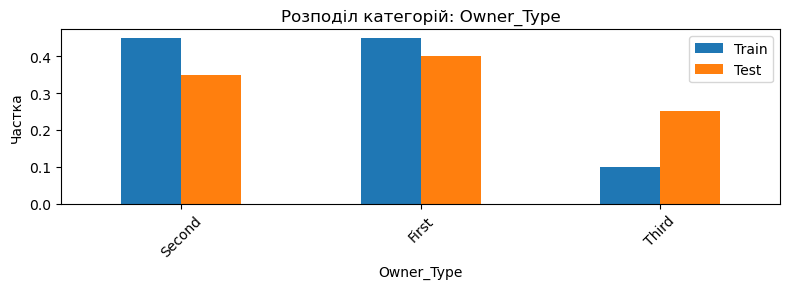

In [167]:
# Категоріальні колонки, спільні для train і test
cat_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns

for col in cat_cols:
    # Порівнюємо частки категорій, а не абсолютні кількості
    train_share = X_train[col].value_counts(normalize=True)
    test_share = X_test[col].value_counts(normalize=True)

    comparison = pd.concat(
        [train_share.rename('Train'), test_share.rename('Test')],
        axis=1
    ).fillna(0)

    comparison.plot(kind='bar', figsize=(8, 3))
    plt.title(f'Розподіл категорій: {col}')
    plt.ylabel('Частка')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [169]:
price_comparison = pd.DataFrame({
    'Train': [
        y_train.mean(),
        y_train.median(),
        y_train.min(),
        y_train.max()
    ],
    'Test': [
        y_test.mean(),
        y_test.median(),
        y_test.min(),
        y_test.max()
    ]
}, index=['Середня ціна', 'Медіана', 'Мінімум', 'Максимум'])

display(price_comparison.round(0))

,Train,Test
Середня ціна,1680000.00,1150000.00
Медіана,1500000.00,850000.00
Мінімум,450000.00,450000.00
Максимум,4000000.00,2700000.00


### Спостереження  
Бачимо що не всі категорії мають рівноцінний розподіл в тест і трейн вибірках, в тому числі і ціна, проте зважаючи що ми маємо лише 100 записів по всім категоріям справедливо не вийде вибірку поділити. 
Тут залишу поділ ціни і колонки трансмісії, потреную модель як є, після чого спробую поділити трансмісію порівну і подивлюсь наскільки змінився прогноз.

**Завдання 6**. Тренуємо лінійну регресію.
0. Видаліть усі НЕчислові колонки з `X_train`, `X_test`, якщо ще цього не зробили.
1. Натренуйте лінійну регресую з `sklearn` на усіх числових даних тренувального набору `X_train`.
2. Зробіть передбачення на  `X_train`, `X_test`. Знайдіть і виведіть root mean squared error відхилення передбачення від справжніх значень цільової змінної.
3. Побудуйте графік розсіювання передбачень проти реальних даних цільової змінної для тренувального і тестувального наборів даних. Що можете сказати про якість моделі?

In [170]:
X_train_num = X_train.select_dtypes(include='number').copy()
X_test_num = X_test.select_dtypes(include='number').copy()

# Переконуємося, що в Train і Test однакові колонки
X_test_num = X_test_num.reindex(columns=X_train_num.columns)

print('Кількість числових ознак:', X_train_num.shape[1])
print('Колонки, які використовуємо:')
print(X_train_num.columns.tolist())

Кількість числових ознак: 20
Колонки, які використовуємо:
['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats', 'Is_Petrol', 'Is_Automatic', 'Audi', 'BMW', 'Ford', 'Honda', 'Hyundai', 'Mahindra', 'Maruti', 'Mercedes', 'Tata', 'Toyota', 'Volkswagen', 'Owner_Type_Codes']


In [171]:
model = LinearRegression()
model.fit(X_train_num, y_train)

LinearRegression()

In [173]:
# Передбачення
y_train_pred = model.predict(X_train_num)
y_test_pred = model.predict(X_test_num)

# RMSE
rmse_train = root_mean_squared_error(y_train, y_train_pred)
rmse_test = root_mean_squared_error(y_test, y_test_pred)

print(f'RMSE Train: {rmse_train:,.2f}')
print(f'RMSE Test:  {rmse_test:,.2f}')

RMSE Train: 210,342.80
RMSE Test:  259,601.27


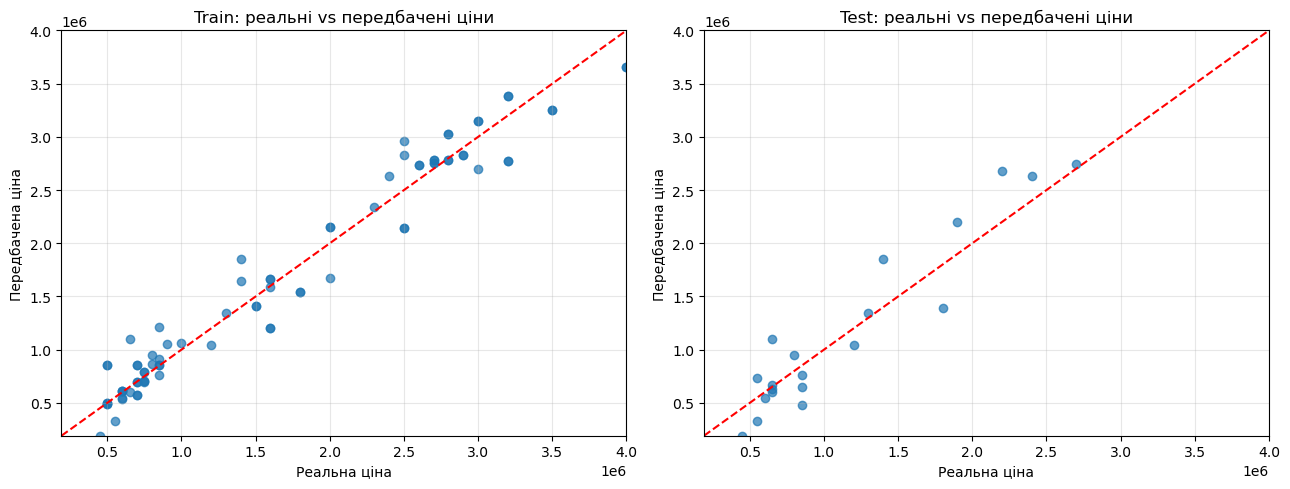

In [174]:
# Спільні межі осей, щоб порівняння було коректним
all_values = np.concatenate([
    np.asarray(y_train),
    np.asarray(y_test),
    y_train_pred,
    y_test_pred
])

min_price = all_values.min()
max_price = all_values.max()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Train
axes[0].scatter(y_train, y_train_pred, alpha=0.7)
axes[0].plot(
    [min_price, max_price],
    [min_price, max_price],
    'r--'
)
axes[0].set_title('Train: реальні vs передбачені ціни')
axes[0].set_xlabel('Реальна ціна')
axes[0].set_ylabel('Передбачена ціна')

# Test
axes[1].scatter(y_test, y_test_pred, alpha=0.7)
axes[1].plot(
    [min_price, max_price],
    [min_price, max_price],
    'r--'
)
axes[1].set_title('Test: реальні vs передбачені ціни')
axes[1].set_xlabel('Реальна ціна')
axes[1].set_ylabel('Передбачена ціна')

for ax in axes:
    ax.set_xlim(min_price, max_price)
    ax.set_ylim(min_price, max_price)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [175]:
from sklearn.metrics import (
    mean_absolute_error,
    r2_score
)
from sklearn.dummy import DummyRegressor

# Метрики нашої моделі
print(f"Train RMSE: {root_mean_squared_error(y_train, y_train_pred):,.0f}")
print(f"Test RMSE:  {root_mean_squared_error(y_test, y_test_pred):,.0f}")
print(f"Test MAE:   {mean_absolute_error(y_test, y_test_pred):,.0f}")
print(f"Test R²:    {r2_score(y_test, y_test_pred):.3f}")

# Базова модель: завжди прогнозує середню ціну Train
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train_num, y_train)

baseline_pred = baseline.predict(X_test_num)

print(
    f"Baseline RMSE: "
    f"{root_mean_squared_error(y_test, baseline_pred):,.0f}"
)

Train RMSE: 210,343
Test RMSE:  259,601
Test MAE:   209,350
Test R²:    0.851
Baseline RMSE: 856,242


### Спостереження  
Бачимо що наша модель трохі гарше дає прогноз на тестових даних, проте в цілому ціну автомобіля ми промахуємось на 250 тис рупій, це набагато краще ніж помилка прогнозу просто середньою ціною. Модель перспективна але є ще над чим працювати.

**Завдання 7**. Ми хочемо проаналізувати як впливає кожен чинник на цілову змінну. Для цього давайте промасштабуємо наші дані.
1. Зробіть масштабування незалежних змінних використовуючи `StandardScaler`. Тренуємо на тренувальних даних, а на тестувальних лише викликаємо `transform`.

2. Натренуйте модель на відмасштабованих даних і перегляньте коефіцієнти моделі. Які колонки є найвпливовішими на формування передбачення з точки зору коефіцієнтів? Проаналізуйте напрям дії найважливіших коефіцієнтів. Чи це логічно з точки зору значення відповідних змінних, що вони впливають на цільову змінну саме в напрямі збільшення / зменшення?

In [176]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Навчаємо scaler тільки на Train
X_train_scaled = scaler.fit_transform(X_train_num)

# До Test застосовуємо ті самі параметри масштабування
X_test_scaled = scaler.transform(X_test_num)

In [177]:
model_scaled = LinearRegression()

model_scaled.fit(X_train_scaled, y_train)

# Таблиця коефіцієнтів
coefficients = pd.DataFrame({
    'Ознака': X_train_num.columns,
    'Коефіцієнт': model_scaled.coef_
})

coefficients['Абсолютний коефіцієнт'] = coefficients['Коефіцієнт'].abs()

coefficients = coefficients.sort_values(
    'Абсолютний коефіцієнт',
    ascending=False
)

display(coefficients)

,Ознака,Коефіцієнт,Абсолютний коефіцієнт
4,Power,500000.51,500000.51
15,Mercedes,209257.74,209257.74
9,BMW,208105.08,208105.08
8,Audi,206123.09,206123.09
6,Is_Petrol,-185245.84,185245.84
12,Hyundai,-151916.05,151916.05
13,Mahindra,-140931.63,140931.63
2,Mileage,-131884.63,131884.63
10,Ford,-119069.16,119069.16
7,Is_Automatic,115153.44,115153.44


In [178]:
display(coefficients.head(10))

,Ознака,Коефіцієнт,Абсолютний коефіцієнт
4,Power,500000.51,500000.51
15,Mercedes,209257.74,209257.74
9,BMW,208105.08,208105.08
8,Audi,206123.09,206123.09
6,Is_Petrol,-185245.84,185245.84
12,Hyundai,-151916.05,151916.05
13,Mahindra,-140931.63,140931.63
2,Mileage,-131884.63,131884.63
10,Ford,-119069.16,119069.16
7,Is_Automatic,115153.44,115153.44


### Спостереження
ТОП 10 коефіцієнтів показує - найвпливовіше є Power - потужність автомобіля що логічно - з ростом потужності росте ціна.  
Далі по впливу йдуть ознаки приналежності до марки Мерседес, БМВ та Ауді - що теж логічно оскільки це більш дорогі преміальні марки.  
Наступний по впливу параметр чи є авто бензиновим - впливає негативно якщо автомобіль бензиновий, що теж логічно бо дизельні авто коштують дорожче.  
Далі знову йдуть марки авто - Хюндай, Махіндра і Форд - приналежність до цих марок знижує вартість авто.  
Mileage	- паливна ефективність авто (кілометрів на літр) тут з ростом кілометрів знижується ціна - логічно бо більш дешеві авто зазвичай мають менший розхід пального.  
Останній з топ 10 критеріїв можна виділити тип трансмісії - відношення до автомату підвищує вартість авто.

Нелогічно виглядають менш впливові критерії    
Owner_Type_Codes - логічно має бути чим менше значення тим вища ціна а у нас навпаки  
Engine - Обєм двигуна теж нелогічний показник тут, має бути вищий показник вища ціна, в моделі вийшло навпаки.  
Year - рік випуску теж нелогічний коефіціент з ростом року має рости ціна а в моделі навпаки.

**Завдання 8.** На тих самих відмасштабованих даних натренуйте модель з `statsmodels`. Виведіть звіт і проаналізуйте p-value коефіцієнтів. Які ознаки є стат значущими на рівні значущості 0.05? Напишіть їх список.

In [179]:
import statsmodels.api as sm
import pandas as pd

# Перетворюємо масштабовані дані назад у DataFrame,
# щоб зберегти назви ознак
X_train_sm = pd.DataFrame(
    X_train_scaled,
    columns=X_train_num.columns,
    index=X_train_num.index
)

# Додаємо константу (intercept)
X_train_sm = sm.add_constant(X_train_sm)

# Навчаємо модель
model_sm = sm.OLS(y_train, X_train_sm).fit()

# Повний статистичний звіт
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.959
Model:                            OLS   Adj. R-squared:                  0.946
Method:                 Least Squares   F-statistic:                     73.14
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           2.34e-34
Time:                        19:52:11   Log-Likelihood:                -1094.0
No. Observations:                  80   AIC:                             2228.
Df Residuals:                      60   BIC:                             2276.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const               1.68e+06   2.72e+0

In [182]:
p_values = pd.DataFrame({
    'Коефіцієнт': model_sm.params,
    'p-value': model_sm.pvalues
})

# Не включаємо константу в рейтинг ознак
p_values = p_values.drop(index='const', errors='ignore')

p_values = p_values.sort_values('p-value')

display(p_values)
significant_features = p_values[p_values['p-value'] < 0.05]

print('Кількість статистично значущих ознак на рівні значущості 0.05:',
      len(significant_features))

display(significant_features)

,Коефіцієнт,p-value
Power,500000.51,0.00
Audi,206123.09,0.00
Mercedes,209257.74,0.00
BMW,208105.08,0.00
Hyundai,-151916.05,0.00
Mahindra,-140931.63,0.00
Is_Petrol,-185245.84,0.00
Maruti,-112786.67,0.00
Ford,-119069.16,0.00
Volkswagen,-93391.36,0.00


Кількість статистично значущих ознак на рівні значущості 0.05: 12


,Коефіцієнт,p-value
Power,500000.51,0.00
Audi,206123.09,0.00
Mercedes,209257.74,0.00
BMW,208105.08,0.00
Hyundai,-151916.05,0.00
Mahindra,-140931.63,0.00
Is_Petrol,-185245.84,0.00
Maruti,-112786.67,0.00
Ford,-119069.16,0.00
Volkswagen,-93391.36,0.00


**Завдання 9**. Натренуйте лінійну регресію з `statsmodels` тільки на ознаках, які виявлись стат. значущими в попередньому завданні. Проаналізуйте показники моделі. Чи значно змінились R2 і Adj. R-squared?

In [185]:
# Залишаємо ознаки з p-value < 0.05
significant_feature_names = p_values.index[
    p_values['p-value'] < 0.05
].tolist()

# Train: беремо тільки значущі ознаки
X_train_selected = X_train_sm[significant_feature_names].copy()
X_train_selected = sm.add_constant(X_train_selected, has_constant='add')

# Навчаємо модель
model_sm_selected = sm.OLS(y_train, X_train_selected).fit()

# Виводимо звіт
print(model_sm_selected.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.951
Model:                            OLS   Adj. R-squared:                  0.943
Method:                 Least Squares   F-statistic:                     109.4
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           4.12e-39
Time:                        20:02:20   Log-Likelihood:                -1100.4
No. Observations:                  80   AIC:                             2227.
Df Residuals:                      67   BIC:                             2258.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          1.68e+06   2.78e+04     60.360   

In [186]:
# Створюємо DataFrame із масштабованих тестових даних
X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X_train_num.columns,
    index=X_test_num.index
)

# Залишаємо ті самі ознаки, що й у Train
X_test_selected = X_test_scaled_df[significant_feature_names].copy()
X_test_selected = sm.add_constant(X_test_selected, has_constant='add')

# Передбачення нової моделі
y_train_pred_selected = model_sm_selected.predict(X_train_selected)
y_test_pred_selected = model_sm_selected.predict(X_test_selected)

# Метрики
metrics_selected = pd.DataFrame({
    'Train': [
        root_mean_squared_error(y_train, y_train_pred_selected),
        mean_absolute_error(y_train, y_train_pred_selected),
        r2_score(y_train, y_train_pred_selected)
    ],
    'Test': [
        root_mean_squared_error(y_test, y_test_pred_selected),
        mean_absolute_error(y_test, y_test_pred_selected),
        r2_score(y_test, y_test_pred_selected)
    ]
}, index=['RMSE', 'MAE', 'R²'])

display(metrics_selected.round(3))

,Train,Test
RMSE,227824.30,233241.86
MAE,178837.82,202988.38
R²,0.95,0.88


In [188]:
# Передбачення на Train і Test
y_train_pred_sm = model_sm.predict(X_train_sm)

X_test_sm = pd.DataFrame(
    X_test_scaled,
    columns=X_train_num.columns,
    index=X_test_num.index
)
X_test_sm = sm.add_constant(X_test_sm, has_constant='add')

y_test_pred_sm = model_sm.predict(X_test_sm)

# Порівняння метрик
metrics_sm = pd.DataFrame({
    'Train': [
        root_mean_squared_error(y_train, y_train_pred_sm),
        mean_absolute_error(y_train, y_train_pred_sm),
        r2_score(y_train, y_train_pred_sm)
    ],
    'Test': [
        root_mean_squared_error(y_test, y_test_pred_sm),
        mean_absolute_error(y_test, y_test_pred_sm),
        r2_score(y_test, y_test_pred_sm)
    ]
}, index=['RMSE', 'MAE', 'R²'])

display(metrics_sm.round(3))

,Train,Test
RMSE,210342.80,259601.27
MAE,159741.91,209350.20
R²,0.96,0.85


### Спостереження
R2 і Adj. R-squared змінились не глобально.   
В моделі зі свіма ознаками:  
AIC:                             2228.  
BIC:                             2276.  
В другій моделі:  
AIC:                             2227.  
BIC:                             2258.  
Бачимо що в моделі лише зі стат значущими ознаками показники краще - тобто кількість ознак краще підібрана.  
Порівнюючи показники першої моделі  
	Train	Test
RMSE	210342.80	259601.27
MAE	159741.91	209350.20
R²	0.96	0.85

І другої моделі зі стат ознаками  
	Train	Test
RMSE	227824.30	233241.86
MAE	178837.82	202988.38
R²	0.95	0.88

Бачимо що на тренувальних даних показники РМСЕ та МАЕ стали гірші, але на тестовій вибірці навпаки покращились. Тобто скоріш за все ми перетренували модель використовуючи всі ознаки, і спрощення покращило прогноз.


**Завдання 10**. Натренуйте лінійну регресію з `statsmodels` на усіх ознаках з масштабованого `X_train`, у яких p_value в завданні 8 менше за `0.25`. Ми таким чином помʼякшили критерій відбору ознак. Проаналізуйте показники моделі. Чи значно змінились R2 і Adj. R-squared порівняно з завданням 8? Яку модель з останніх 3х завдань ви б лишили для використання?

In [191]:
# Залишаємо ознаки з p-value < 0.25
significant_feature_names_025 = p_values.index[
    (p_values['p-value'] < 0.25) &
    (p_values.index != 'const')
].tolist()

print('Кількість обраних ознак:', len(significant_feature_names_025))
print('Обрані ознаки:', significant_feature_names_025)

# Train: беремо тільки обрані ознаки
X_train_selected_025 = X_train_sm[
    significant_feature_names_025
].copy()

X_train_selected_025 = sm.add_constant(
    X_train_selected_025,
    has_constant='add'
)

# Навчаємо модель
model_sm_025 = sm.OLS(
    y_train,
    X_train_selected_025
).fit()

# Виводимо звіт
print(model_sm_025.summary())

Кількість обраних ознак: 15
Обрані ознаки: ['Power', 'Audi', 'Mercedes', 'BMW', 'Hyundai', 'Mahindra', 'Is_Petrol', 'Maruti', 'Ford', 'Volkswagen', 'Is_Automatic', 'Mileage', 'Honda', 'Kilometers_Driven', 'Tata']
                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.958
Model:                            OLS   Adj. R-squared:                  0.948
Method:                 Least Squares   F-statistic:                     97.03
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           4.85e-38
Time:                        00:04:46   Log-Likelihood:                -1094.7
No. Observations:                  80   AIC:                             2221.
Df Residuals:                      64   BIC:                             2260.
Df Model:                          15                                         
Covariance Type:            nonrobust                                       

In [192]:
# Створюємо DataFrame із масштабованих тестових даних
X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X_train_num.columns,
    index=X_test_num.index
)

# Залишаємо ті самі ознаки, що й у Train
X_test_selected_025 = X_test_scaled_df[
    significant_feature_names_025
].copy()

X_test_selected_025 = sm.add_constant(
    X_test_selected_025,
    has_constant='add'
)

# Передбачення нової моделі
y_train_pred_025 = model_sm_025.predict(X_train_selected_025)
y_test_pred_025 = model_sm_025.predict(X_test_selected_025)

# Метрики
metrics_025 = pd.DataFrame({
    'Train': [
        root_mean_squared_error(y_train, y_train_pred_025),
        mean_absolute_error(y_train, y_train_pred_025),
        r2_score(y_train, y_train_pred_025)
    ],
    'Test': [
        root_mean_squared_error(y_test, y_test_pred_025),
        mean_absolute_error(y_test, y_test_pred_025),
        r2_score(y_test, y_test_pred_025)
    ]
}, index=['RMSE', 'MAE', 'R²'])

display(metrics_025.round(3))

,Train,Test
RMSE,212184.26,250977.95
MAE,161060.70,204835.00
R²,0.96,0.86


Всі ознаки
R-squared:                       0.959  
Adj. R-squared:                  0.946  

0,05 ознаки  
R-squared:                       0.951  
Adj. R-squared:                  0.943  

0,25 ознаки  
R-squared:                       0.958  
Adj. R-squared:                  0.948  

При використанні ознак 0,25 показники R2 і Adj. R-squared трохи зросли від 0,05 але не глобально, майже на рівні моделі всіх ознак.  




Всі ознаки  
 	    Train	     Test
RMSE	210342.80	259601.27
MAE	    159741.91	209350.20
R²   	0.96    	0.85

0,05 ознаки  
 	    Train	Test
RMSE	227824.30	233241.86
MAE  	178837.82	202988.38
R²	    0.95	    0.88

0,25 ознаки  
	   Train	       Test
RMSE	212184.26	250977.95
MAE  	161060.70	204835.00
R²	    0.96	    0.86

Після відбору ознак за p-value < 0.05 тренувальна помилка зросла до 227824, зате тестова зменшилася до 233242. Це узгоджується з тим, що простіша модель краще узагальнює закономірності та менше пристосовується до особливостей навчальних даних.

Модель з порогом 0.25 зберігає більше ознак і має кращі тренувальні метрики, але на тесті поступається моделі з порогом 0.05.
Тому фінально я б лишила другу модель з набором стат значимих ознак (0,05)